# E108 · One day is not your diet: usual salt intake from two 24-hour recalls

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: **NHANES 2017-2018** (CDC / National Center for Health Statistics; US federal work, public domain). Two 24-hour dietary recalls (DR1TOT_J in person, DR2TOT_J by telephone 3-10 days later) for the 4,863 adults aged 19 and over with a reliable first recall, 4,240 of them with a reliable second one, joined to demographics (DEMO_J) and the alcohol questionnaire (ALQ_J), with the dietary survey weights. Derived by `tools/build_e108_nhanes.py` |
| **You will learn** | **Usual intake** as a latent quantity and each recall as a noisy measurement of it · **replicate-measurement deconvolution** (the ISU and NCI methods) as a hierarchical model · a **Box-Cox** scale and the **back-transform** to milligrams by Gauss-Hermite quadrature · why removing noise can *raise* the share over a line · a centred / non-centred **mixed parameterisation** of two variance hierarchies · integrating person effects out to see exactly what a **replicate identifies** · a **correlated two-part (hurdle) model** for alcohol, with a questionnaire for the never-drinkers · survey weights in a population share · a **hypothetical outcome plot (HOP)** as a shareable GIF, icon arrays with honest uncertainty, a frequency tree and a calibrated-language strip |

## In plain words

**The question.** About nine in ten US adults reportedly eat more than the advised 2,300 mg of
sodium a day, about a teaspoon of salt. But diets change from day to day: is that right?

**What we did.** A national survey asked 4,863 adults what they ate the day before, most of them
twice. Each person's *usual* intake, their long-run average, is hidden; each day
is that plus the day's ups and downs. Two days per person let the model separate how much people
differ from how much one person's days differ, and set the daily part aside.

**What we found.** Judged by one day, 74 in 100 adults are over the line; judged by their usual
diet, about 86 in 100 (85 to 88): many who look under it just had a light day. So the CDC's
nine in ten is close; one day would have said three in four.

**How sure are we.** It is *virtually certain* (>99%) that more adults are usually over the line
than a single day suggests. We have *medium confidence* in the 86 in 100 itself: two days per
person is the minimum, recalls miss salt added at the table, and our ranges are probably a
little too narrow.

![Animated figure: two grids of 100 dots, each dot one percent of US adults, orange if over 2,300
mg of sodium and blue if under. The left grid, judged by one day, flickers all over from frame to
frame, with 65 to 78 dots over in nine frames out of ten; the right grid, judged by usual diet,
changes only in the few dots at the line and stays at 84 to 88 over.](E108_usual_salt_intake.gif)

*The animation is saved as `E108_usual_salt_intake.gif`; part G builds it and shows six of its
frames as a still for print.*

In [1]:
import os

for v_ in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[v_] = "1"  # nutpie runs chains as threads: a BLAS pool per chain would fight over the cores

import logging
import sys
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from matplotlib.patches import Patch
from scipy import stats

from pymc_challenges import data
from pymc_challenges import public as pub

RANDOM_SEED = 108
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="arviz")
sys.modules.pop("jax", None)  # arviz leaves a lazy jax stub that makes matplotlib import all of JAX
pd.set_option("display.width", 160)
T_START, TIMES = time.time(), {}

HI, LO, INK, MUTED, LIGHT = pub.HI, pub.LO, pub.INK, pub.MUTED, pub.LIGHT
LINE = 2300.0                                   # mg sodium a day: the adult CDRR / Dietary Guidelines limit
STEM = "E108_usual_salt_intake"
print(f"PyMC {pm.__version__}, ArviZ {az.__version__}")

PyMC 6.3.2, ArviZ 1.3.0


## The setting

"Nine in ten Americans eat too much salt" is one of the most repeated numbers in public health. It
comes from the National Health and Nutrition Examination Survey (NHANES), in which trained
interviewers walk each participant through everything they ate and drank in the previous 24 hours,
food by food, and a nutrient database turns the list into milligrams. The limit is 2,300 mg of
sodium a day for adults, the intake above which the National Academies (2019) judged that cutting
back lowers the risk of chronic disease.

A 24-hour recall measures one day, and one day is a poor guide to a diet. Pizza night and a day of
salad are both real days of the same person. If we count everyone whose recall day was over 2,300
mg, we count the person whose usual intake is 2,000 mg but who had pizza, and miss the person
whose usual intake is 2,600 mg but who ate lightly. Statisticians in nutrition have worried about
this for a long time. Carriquiry (1999) showed why the share of people past a cut-off, computed
from single days, is biased, and the remedy has a name: estimate the **usual intake**
distribution. The Iowa State (ISU) method of Nusser, Carriquiry, Dodd & Fuller (1996) transforms
intakes towards normality, splits their variance into a between-person and a within-person part
using people with a second recall, and keeps only the first. The NCI method (Tooze et al. 2006;
Kipnis et al. 2009) adds covariates and handles foods eaten only on some days with a two-part
model; Dodd et al. (2006) review the family. NHANES collects a second recall on most participants
for exactly this reason.

This is a measurement-error model, and in PyMC it is a hierarchical model. Person $i$ has a hidden
usual level $\mu_i$; each recall day $j$ is a noisy reading,

$$y_{ij} = \mu_i + \text{(day effects)} + \varepsilon_{ij},\qquad \varepsilon_{ij}\sim N(0,\sigma_w^2),\qquad
\mu_i \sim N(x_i^\top\beta,\ \sigma_b^2),$$

on a scale $y = g(\text{sodium})$ where the noise is close to normal. The between-person spread
$\sigma_b$ is what we want; the within-person spread $\sigma_w$ is what one day adds on top, and
only people with two days can tell the two apart. The share of the population over the line is
then a property of the distribution of $\mu_i$, back on the milligram scale.

The textbook expectation is that one-day shares exaggerate: the noisy distribution is wider than
the usual one, so it has more people at both ends. Look at where the line sits, though. If most
people's usual intake is *above* the line, a wider distribution pushes more of them *below* it,
and the one-day share comes out too *low*. Which way the bias goes depends on where the line cuts
the distribution, and the CDC's own "nine in ten" is not a one-day number: Jackson, King, Zhao &
Cogswell (2016, *MMWR* 64:1393-1397) estimated usual intakes from the two NHANES 2009-2012 recalls
with the NCI method and found 89% of adults over 2,300 mg (98% of men, 80% of women). Our question
is whether the 2017-2018 data, modelled from scratch, agree, and how far a single day would have
taken us from that answer.

| part | question | tool |
|---|---|---|
| A | What do two days of eating look like? | the recalls, survey weights, day 1 against day 2, the one-day share |
| B | Can a model take the day-to-day noise away? | a toy deconvolution with a known truth |
| C | A usual-intake model for sodium | a Box-Cox scale, prior predictive check, a funnel and its fix, a prior swap, predictive checks of one day and of two |
| D | What changes, and for whom? | the back-transform, three lines, a log-scale refit, sex and income |
| E | What does the second day buy? | person effects integrated out; refits with one day and with 300 second days; income-specific variances |
| F | Alcohol: zeros that mean "not today" | a correlated two-part model with a never-drinker group; a frequency tree |
| G | Explaining it to everyone | the HOP GIF, its still, flip rates, an icon-array ladder, a word strip, and the statistician's plot beside them |

## A · Two days of eating

### The recalls

The derived file holds one row per adult and reliable recall day: total sodium, potassium, alcohol
and energy for the day, the day of the week, age, sex, the family income-to-poverty ratio, race
and ethnicity, the alcohol questionnaire, and the dietary sample weights.

In [2]:
data.describe("e108_nhanes_recalls")
raw = data.load("e108_nhanes_recalls")
print(f"{len(raw):,} recall days from {raw.seqn.nunique():,} adults; "
      f"{(raw.groupby('seqn').day.count() == 2).sum():,} with both days")
print("days with zero sodium:", int((raw.sodium_mg <= 0).sum()))

e108_nhanes_recalls: One row per adult and reliable recall day (9,103 rows: 4,863 adults, 4,240 with day 2): seqn, day (1 or 2), dow (1 = Sunday ... 7 = Saturday), sodium_mg, potassium_mg, alcohol_g, kcal, age (years, top-coded 80), sex, pir (family income-to-poverty ratio, top-coded 5, NaN for 572 adults), race_eth (RIDRETH3 code: 1 Mexican American, 2 other Hispanic, 3 NH White, 4 NH Black, 6 NH Asian, 7 other/multi), alq_ever (ALQ111 ever had a drink: 1 yes, 0 never, NaN unknown), alq_freq (ALQ121 past-year drinking frequency code 0-10: 0 none in the past year, also set for lifetime abstainers, 1 every day ... 10 once or twice a year, NaN refused/unknown), alq_drinks (ALQ130 usual drinks on a drinking day, NaN refused/unknown/not asked), wt_day1 / wt_day2 (dietary day-1 and two-day sample weights), psu, stratum (masked design variables).
  source: NHANES 2017-2018 (cycle J), CDC / National Center for Health Statistics: total nutrient intakes from the day-1 (in person) and day-2 (tel

One adult reports 0 mg of sodium for a whole (reliable) day; we drop that single day, which leaves
that person with their second day only. We group people for the variance parts of the model into
eight cells of age band by sex, and code income into bands of the income-to-poverty ratio (below
the poverty line, 1-2, 2-3, 3-4, 4 or more times it, and unknown for the 572 adults without one).
The weekend (Friday to Sunday) gets its own term: NHANES schedules weekend recalls on purpose, and
eating differs on those days.

In [3]:
AGE_EDGES, AGE_LAB = [18, 30, 50, 70, 81], ["19-30", "31-50", "51-70", "71+"]
PIR_EDGES, PIR_LAB = [0, 1, 2, 3, 4, 5.01], ["<1", "1-2", "2-3", "3-4", "4+", "unknown"]
RACE = {1: "Mexican Am.", 2: "Other Hisp.", 3: "NH White", 4: "NH Black", 6: "NH Asian", 7: "Other/multi"}
RACES = list(RACE.values())
CELLS = [f"{a} {s}" for a in AGE_LAB for s in ("female", "male")]

d = raw[raw.sodium_mg > 0].copy()
per = d.sort_values("day").groupby("seqn").first().reset_index()
per = per[["seqn", "age", "sex", "pir", "race_eth", "alq_freq", "wt_day1"]]
per["age_g"] = pd.cut(per.age, AGE_EDGES, labels=AGE_LAB).astype(str)
pb = pd.cut(per.pir, PIR_EDGES, labels=PIR_LAB[:5], right=False).astype(object)
per["pir_g"] = pb.where(per.pir.notna(), "unknown").astype(str)
per["cell"] = per.age_g + " " + per.sex
per["race"] = per.race_eth.map(RACE)
d["p"] = pd.Index(per.seqn).get_indexer(d.seqn)
d["weekend"] = d.dow.isin([1, 6, 7]).astype(float)       # Sunday, Friday, Saturday
d = d.reset_index(drop=True)
CI = pd.Index(CELLS).get_indexer(per.cell)
PI = pd.Index(PIR_LAB).get_indexer(per.pir_g)
RI = pd.Index(RACES).get_indexer(per.race)
assert (d.p >= 0).all() and (CI >= 0).all() and (PI >= 0).all() and (RI >= 0).all()
W = per.wt_day1.to_numpy() / per.wt_day1.sum()           # day-1 dietary weights, one per adult
N = len(per)

d1 = d[d.day == 1]
x1, p1 = d1.sodium_mg.to_numpy(float), d1.p.to_numpy()
w1 = W[p1]
ONE_DAY = np.average(x1 > LINE, weights=w1)
print(f"{N:,} adults, {len(d):,} sodium days; weekend share of day-1 recalls {d1.weekend.mean():.0%}")
print(f"one-day share over {LINE:,.0f} mg: weighted {ONE_DAY:.3f}, unweighted {(x1 > LINE).mean():.3f}")
wkd1 = d1.weekend.to_numpy() == 1
w_dow = np.where(wkd1, (3 / 7) / wkd1.mean(), (4 / 7) / (1 - wkd1.mean()))   # weekday mix only
print(f"weekend share of day-1 recalls after weighting {np.average(wkd1, weights=w1):.0%}; "
      f"share over re-weighted for day of week only {np.average(x1 > LINE, weights=w_dow):.3f}")
for lab, m_ in (("weekdays", ~wkd1), ("weekends", wkd1)):
    print(f"  {lab}: unweighted {(x1[m_] > LINE).mean():.3f}, weighted {np.average(x1[m_] > LINE, weights=w1[m_]):.3f}")
print(pd.Series(PIR_LAB, name="pir band").to_frame().assign(
    adults=[int((PI == j).sum()) for j in range(6)],
    one_day_over=[round(np.average(x1[PI[p1] == j] > LINE, weights=w1[PI[p1] == j]), 3) for j in range(6)]
).to_string(index=False))


def wquant(x, w, q):
    """Weighted quantiles (q may be an array)."""
    o = np.argsort(x)
    c = np.cumsum(w[o]) / w[o].sum()
    return x[o][np.minimum(np.searchsorted(c, q), len(x) - 1)]


print("weighted one-day percentiles 5/50/95 (mg):", wquant(x1, w1, [0.05, 0.5, 0.95]).round())

4,863 adults, 9,102 sodium days; weekend share of day-1 recalls 63%
one-day share over 2,300 mg: weighted 0.740, unweighted 0.708
weekend share of day-1 recalls after weighting 42%; share over re-weighted for day of week only 0.702
  weekdays: unweighted 0.691, weighted 0.732
  weekends: unweighted 0.718, weighted 0.751
pir band  adults  one_day_over
      <1     810         0.668
     1-2    1196         0.695
     2-3     709         0.755
     3-4     468         0.779
      4+    1108         0.783
 unknown     572         0.696
weighted one-day percentiles 5/50/95 (mg): [1192. 3204. 7041.]


Weighted to the US adult population, **74% of single recall days are over 2,300 mg** (2,300 mg of
sodium is about a teaspoon of salt). The weights move the share up three points from the 71%
unweighted, and not because of the weekend. NHANES schedules weekend recalls on purpose (63% of
first recalls, 42% after weighting), and weekend days read higher, so undoing that excess alone
would *lower* the share slightly, to 70%. The weights raise it on weekdays and weekends alike
(69% to 73%, 72% to 75%), because they undo the survey's oversampling of groups that report less
sodium. We meet this again when the model reproduces the weighted share. The weighted median day
is about 3,200 mg, well above the line, and the 5th to 95th percentiles run from about 1,200 to
7,000 mg. Across income bands the one-day share climbs from 67% below the poverty line to 78% at
four times it; we come back to that gap in part D.

### Day 1 against day 2

The people with two recalls show how far one day is from the next. On the log scale, two days of
the same person should agree to the extent that people differ more than days do; their correlation
is the share of the one-day variance that belongs to the person.

4,239 adults with two days: log-scale correlation 0.39
method of moments on the log scale: within 0.203, between 0.128, ratio 1.6; mean log day 2 minus day 1 -0.097
over on both days 53%, on one day only 31%, on neither 17%  (unweighted)


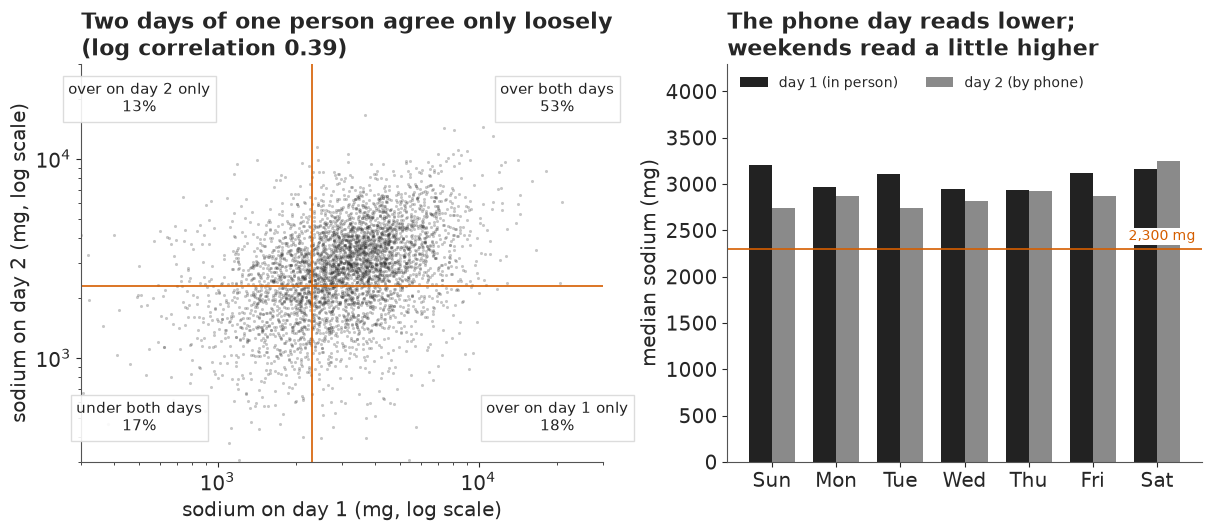

In [4]:
both = d.pivot_table(index="p", columns="day", values="sodium_mg").dropna()
l1, l2 = np.log(both[1].to_numpy()), np.log(both[2].to_numpy())
r = np.corrcoef(l1, l2)[0, 1]
within = np.var(l2 - l1 - (l2 - l1).mean()) / 2
between = np.cov(l1, l2)[0, 1]
print(f"{len(both):,} adults with two days: log-scale correlation {r:.2f}")
print(f"method of moments on the log scale: within {within:.3f}, between {between:.3f}, "
      f"ratio {within / between:.1f}; mean log day 2 minus day 1 {np.mean(l2 - l1):+.3f}")
o1, o2 = both[1].to_numpy() > LINE, both[2].to_numpy() > LINE
print(f"over on both days {np.mean(o1 & o2):.0%}, on one day only {np.mean(o1 != o2):.0%}, "
      f"on neither {np.mean(~o1 & ~o2):.0%}  (unweighted)")

fig, axs = plt.subplots(1, 2, figsize=(12, 5.2), width_ratios=[1.1, 1])
ax = axs[0]
ax.scatter(both[1], both[2], s=5, alpha=0.25, color=INK, lw=0)
for f in (ax.axvline, ax.axhline):
    f(LINE, color=LO, lw=1.2)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(300, 30000); ax.set_ylim(300, 30000)
ax.set_xlabel("sodium on day 1 (mg, log scale)"); ax.set_ylabel("sodium on day 2 (mg, log scale)")
ax.set_title(f"Two days of one person agree only loosely\n(log correlation {r:.2f})", loc="left")
for (x, y, t) in [(20000, 20000, f"over both days\n{np.mean(o1 & o2):.0%}"),
                  (500, 500, f"under both days\n{np.mean(~o1 & ~o2):.0%}"),
                  (20000, 500, f"over on day 1 only\n{np.mean(o1 & ~o2):.0%}"),
                  (500, 20000, f"over on day 2 only\n{np.mean(~o1 & o2):.0%}")]:
    ax.text(x, y, t, ha="center", va="center", fontsize=10.5, color=INK,
            bbox=dict(fc="white", ec=LIGHT, alpha=0.9))
ax = axs[1]
DOW = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
for day, col, off in ((1, INK, -0.18), (2, MUTED, 0.18)):
    g = d[d.day == day].groupby("dow").sodium_mg
    med, n = g.median(), g.size()
    ax.bar(np.arange(7) + off, med.reindex(range(1, 8)).to_numpy(), width=0.36, color=col,
           label=f"day {day} ({'in person' if day == 1 else 'by phone'})")
ax.axhline(LINE, color=LO, lw=1.2)
ax.text(6.6, LINE + 60, "2,300 mg", color=LO, ha="right", va="bottom", fontsize=10,
        bbox=dict(fc="white", ec="none", pad=1))
ax.set_xticks(range(7), DOW)
ax.set_ylabel("median sodium (mg)")
ax.set_ylim(0, 4300)
ax.legend(loc="upper left", fontsize=10, frameon=False, ncols=2)
ax.set_title("The phone day reads lower;\nweekends read a little higher", loc="left");

The cloud is wide: the log correlation between two days of the same person is 0.39. In the
language of the model, about 40% of the one-day variance on this scale is the person and 60% is
the day (method-of-moments within / between ratio 1.6). Almost a third of adults (31%) are over
the line on one of their two days and under it on the other. The second recall, taken by
telephone, also reads about 9% lower on average, a known feature of NHANES (people report less on
the phone, or the days differ); the model gets a day-2 term rather than treating it as noise.

The counts in the corners already hint at the answer. 53% of people are over on both days and
only 17% under on both: the bulk sits above the line, and most of the people who cross it are
people from above it having a light day.

## B · A toy deconvolution

Before the real model, a world where we know the truth. We simulate 500 people whose usual sodium
intakes have a median of 3,300 mg, like real adults, and give each two noisy days with twice as
much within-person as between-person variance on the log scale. Then we fit the model

$$\log x_{ij} \sim N(\mu_i, \sigma_w^2), \qquad \mu_i = a + \sigma_b u_i,\quad u_i\sim N(0,1),$$

and compute each person's usual intake on the milligram scale. That last step is easy to get
wrong. Usual intake is the long-run **mean** of a person's days, and the mean of a log-normal day
is $E[x \mid \mu_i] = \exp(\mu_i + \sigma_w^2/2)$, not $\exp(\mu_i)$, which is the person's
*median* day.

In [5]:
t0 = time.time()
rs = np.random.default_rng(1)
n_toy, sb_true, sw_true = 500, 0.30, 0.42
mu_true = np.log(3300) - sw_true**2 / 2 + sb_true * rs.standard_normal(n_toy)   # log median day
usual_true = np.exp(mu_true + sw_true**2 / 2)                                     # mean day, mg
toy = np.exp(mu_true[:, None] + sw_true * rs.standard_normal((n_toy, 2)))
with pm.Model(coords={"person": np.arange(n_toy), "day": [1, 2]}) as toy_model:
    a = pm.Normal("a", np.log(3000), 1)
    s_b = pm.HalfNormal("s_b", 1)
    s_w = pm.HalfNormal("s_w", 1)
    u = pm.Normal("u", 0, 1, dims="person")
    pm.Normal("y", (a + s_b * u)[:, None], s_w, observed=np.log(toy), dims=("person", "day"))
    toy_idata = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
post_toy = az.extract(toy_idata, var_names=["a", "s_b", "s_w", "u"], num_samples=1000, random_seed=1)
mu_toy = (post_toy["a"].values + post_toy["s_b"].values * post_toy["u"].values).T      # (S, person)
usual_toy = np.exp(mu_toy + post_toy["s_w"].values[:, None] ** 2 / 2)
print(f"divergences {int(toy_idata.sample_stats['diverging'].sum())}, "
      f"max r_hat {max(float(az.rhat(toy_idata, var_names=[v]).to_dataset()[v].max()) for v in ['a', 's_b', 's_w', 'u']):.3f}")
print(az.summary(toy_idata, var_names=["s_b", "s_w"], round_to=3)[["mean", "sd", "eti89_lb", "eti89_ub", "r_hat"]])
print(f"truth: s_b {sb_true}, s_w {sw_true}; realised in this sample: sd of usual levels "
      f"{mu_true.std():.3f}, sd of day noise {np.std(np.log(toy) - mu_true[:, None]):.3f}")
for lab, f in [("over 2,300 mg", lambda v: v > LINE), ("under 1,500 mg", lambda v: v < 1500),
               ("over 5,000 mg", lambda v: v > 5000)]:
    est = f(usual_toy).mean(1)
    print(f"{lab:15s} true usual {f(usual_true).mean():.3f}   day 1 {f(toy[:, 0]).mean():.3f}   "
          f"model {np.median(est):.3f} ({np.quantile(est, 0.055):.3f}-{np.quantile(est, 0.945):.3f})")
TIMES["toy"] = time.time() - t0

divergences 0, max r_hat 1.008
      mean     sd  eti89_lb  eti89_ub  r_hat
s_b  0.281  0.024     0.243     0.319  1.003
s_w  0.449  0.014     0.427     0.471  1.001
truth: s_b 0.3, s_w 0.42; realised in this sample: sd of usual levels 0.274, sd of day noise 0.442
over 2,300 mg   true usual 0.908   day 1 0.664   model 0.886 (0.850-0.926)
under 1,500 mg  true usual 0.004   day 1 0.080   model 0.002 (0.000-0.010)
over 5,000 mg   true usual 0.058   day 1 0.136   model 0.060 (0.034-0.084)


The model recovers the split. Its between-person sd covers the truth; its within-person sd,
0.45, is above the nominal 0.42 but matches the 0.44 of noise this sample actually drew,
which is what two days can see. With them come the shares. In this toy world 91% of people usually
eat over 2,300 mg; a single day says 66%, and the model, from the same two days, says about 89%
(85-93%). The tails go the other way: one day finds 8% of people under 1,500 mg where the truth is
under 1%, and 14% over 5,000 mg where the truth is 6%; the model gets both. Same data, same noise,
opposite biases, all depending on which side of the middle the line falls. The picture makes it
plain.

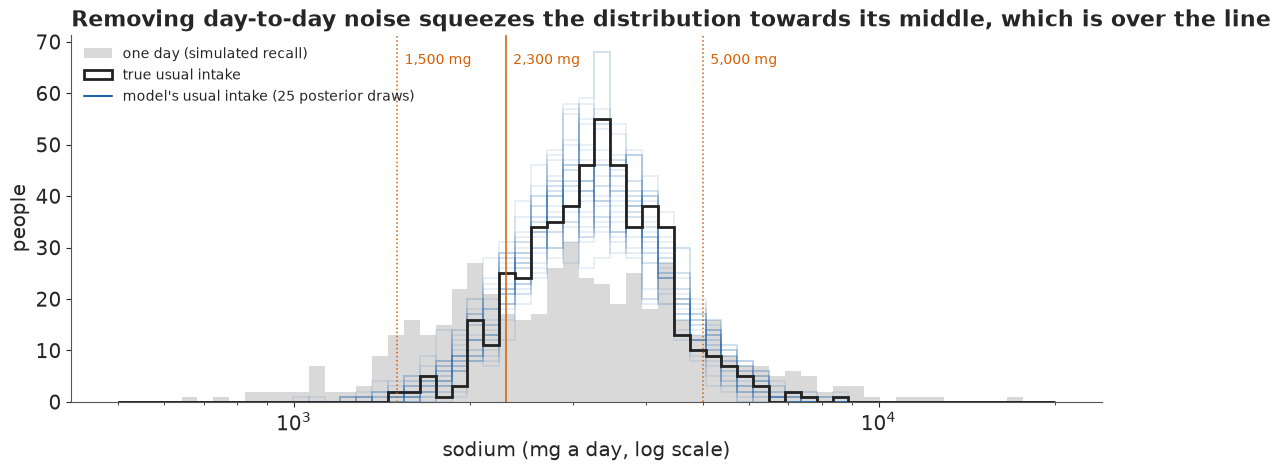

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.6))
bins = np.geomspace(500, 20000, 60)
ax.hist(toy[:, 0], bins=bins, color=LIGHT, label="one day (simulated recall)")
ax.hist(usual_true, bins=bins, histtype="step", lw=2, color=INK, label="true usual intake")
for k in range(25):
    h, _ = np.histogram(usual_toy[k], bins=bins)
    ax.stairs(h, bins, color=HI, alpha=0.12, lw=1.2)
ax.plot([], [], color=HI, lw=1.5, label="model's usual intake (25 posterior draws)")
for v, t in ((1500, "1,500"), (LINE, "2,300"), (5000, "5,000")):
    ax.axvline(v, color=LO, lw=1.1, ls="-" if v == LINE else ":")
    ax.text(v * 1.03, ax.get_ylim()[1] * 0.92, t + " mg", color=LO, fontsize=10)
ax.set_xscale("log")
ax.set_xlabel("sodium (mg a day, log scale)"); ax.set_ylabel("people")
ax.legend(loc="upper left", fontsize=10, frameon=False)
ax.set_title("Removing day-to-day noise squeezes the distribution towards its middle, which is over the line",
             loc="left");

## C · A usual-intake model for sodium

### A scale where the noise is normal

The log is the usual first choice for intakes, but on the log scale real sodium days are skewed to
the *left*: a few very light days stretch the lower tail. Nusser et al. (1996) transform intakes
with a power before modelling, and so do we. A Box-Cox transform
$g_\lambda(x) = (x^\lambda - 1)/\lambda$ includes the log at $\lambda = 0$; we take $\lambda$ from
its maximum-likelihood value on day 1, then standardise.

In [7]:
x_all = d.sodium_mg.to_numpy(float)
LAM = float(stats.boxcox_normmax(x1))
zbc = (x_all**LAM - 1) / LAM
M0, S0 = zbc[d.day.to_numpy() == 1].mean(), zbc[d.day.to_numpy() == 1].std()
Y = (zbc - M0) / S0
for lab, v in (("log", np.log(x1)), (f"Box-Cox {LAM:.2f}", (x1**LAM - 1) / LAM)):
    print(f"{lab:13s} skewness {stats.skew(v):+.2f}, excess kurtosis {stats.kurtosis(v):.2f}")


def ginv(zs):
    """Standardised Box-Cox scale -> mg."""
    return np.maximum(LAM * (zs * S0 + M0) + 1, 1e-12) ** (1 / LAM)

log           skewness -1.10, excess kurtosis 6.42
Box-Cox 0.30  skewness +0.09, excess kurtosis 1.14


The log leaves a skewness of -1.1 and an excess kurtosis of 6.4; $\lambda \approx 0.30$ (between a
cube root and a square root) removes the skew (+0.09) and most of the excess kurtosis (1.1 is
left, so the tails are still a little heavier than a normal's; we meet them again in the
predictive checks and in the first exercise). On this standardised scale one-day values have
mean 0 and sd 1, which makes priors easy to state.

### The model

For person $i$ in variance cell $c(i)$ (age band by sex), recall day $j$:

$$y_{ij} \sim N\big(\mu_i + \gamma_2[j=2] + \gamma_w(\text{weekend}_{ij} - 3/7),\ \sigma_{w,c(i)}^2\big),$$
$$\mu_i = a + \beta_{c(i)} + \beta_{\text{income}(i)} + \beta_{\text{race}(i)} + \sigma_{b,c(i)}\,u_i,
\qquad u_i \sim N(0, 1).$$

The group effects are zero-sum normals. The day-2 term absorbs the phone-day drop, and the weekend
term is centred at 3/7, so $\mu_i$ is the level of an average day of a week. Each cell has its own
within-person and between-person sd, and both sets are partially pooled on the log scale:
$\log\sigma_{w,c}\sim N(\ell_w, \tau_w^2)$ and $\log\sigma_{b,c}\sim N(\ell_b, \tau_b^2)$. The
priors on $\ell_w$ and $\ell_b$ centre the within / between variance ratio at $(0.75/0.6)^2
\approx 1.6$. That centre is not independent of the data: it is the method-of-moments ratio we
computed on the log scale in part A. The prior is wide enough (the prior predictive check below
gives the ratio a range from about a sixth to 18) that the data should decide, and after the fit
we refit with the prior centred at a ratio of 1 to check that they do.

A *usual intake* in milligrams is then the mean over day noise and over a typical week (four
weekdays, three weekend days):

$$T_i = \tfrac47\,E\big[g^{-1}(\mu_i - \tfrac37\gamma_w + \sigma_w\varepsilon)\big]
+ \tfrac37\,E\big[g^{-1}(\mu_i + \tfrac47\gamma_w + \sigma_w\varepsilon)\big],\qquad \varepsilon\sim N(0,1),$$

computed with 24-node Gauss-Hermite quadrature. The in-person day 1 is the reference: we do not
add the phone-day drop to anyone's usual intake.

In [8]:
P_ARR, DAY2 = d.p.to_numpy(), (d.day.to_numpy() == 2).astype(float)
WK = d.weekend.to_numpy() - 3 / 7
COORDS = {"person": per.seqn.to_numpy(), "cell": CELLS, "pir": PIR_LAB, "race": RACES}


def sodium_model(centred_between=False, y=Y, sw_centre=0.75):
    """The sodium model on scale y; sw_centre/0.6 squared is the prior centre of the variance ratio."""
    with pm.Model(coords=COORDS) as m:
        a = pm.Normal("a", 0, 1)
        b_cell = pm.ZeroSumNormal("b_cell", 0.5, dims="cell")
        b_pir = pm.ZeroSumNormal("b_pir", 0.5, dims="pir")
        b_race = pm.ZeroSumNormal("b_race", 0.5, dims="race")
        g_day2 = pm.Normal("g_day2", 0, 0.5)
        g_wk = pm.Normal("g_wk", 0, 0.5)
        ls_w0 = pm.Normal("ls_w0", np.log(sw_centre), 0.5)
        ls_b0 = pm.Normal("ls_b0", np.log(0.6), 0.5)
        t_w = pm.HalfNormal("t_w", 0.3)
        t_b = pm.HalfNormal("t_b", 0.3)
        ls_w = pm.Normal("ls_w", ls_w0, t_w, dims="cell")                     # centred
        if centred_between:
            ls_b = pm.Normal("ls_b", ls_b0, t_b, dims="cell")
        else:                                                                # non-centred
            ls_b = pm.Deterministic("ls_b", ls_b0 + t_b * pm.Normal("e_b", 0, 1, dims="cell"), dims="cell")
        s_w = pm.Deterministic("s_w", pt.exp(ls_w), dims="cell")
        s_b = pm.Deterministic("s_b", pt.exp(ls_b), dims="cell")
        u = pm.Normal("u", 0, 1, dims="person")
        mu = a + b_cell[CI] + b_pir[PI] + b_race[RI] + s_b[CI] * u
        pm.Normal("y", mu[P_ARR] + g_day2 * DAY2 + g_wk * WK, s_w[CI][P_ARR], observed=y)
    return m

### Prior predictive check

What do these priors say about one-day intakes, before seeing any? We draw 300 sets of parameters
and recall days, back-transform to milligrams, and look at the median day and the share over the
line in each.

prior median day (mg):       [1130. 3140. 6810.]
prior share over 2,300 mg:   [0.22 0.65 0.94]
prior 99th percentile (mg):  [ 6000. 14300. 32100.]
prior within/between ratio:  [ 0.17  1.86 17.8 ]
share of prior days at the Box-Cox floor (x = 0): 0.0020


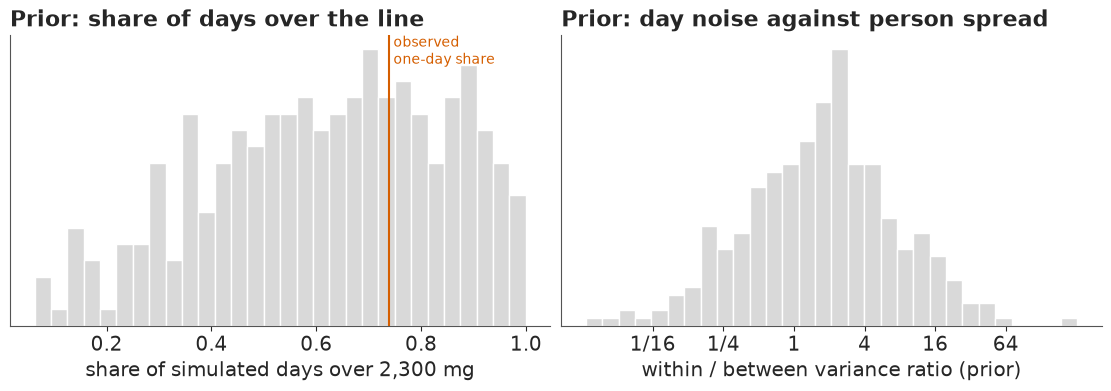

In [9]:
t0 = time.time()
m_sod = sodium_model()
with m_sod:
    prior = pm.sample_prior_predictive(300, random_seed=RANDOM_SEED, var_names=["y", "s_w", "s_b"])
yp = prior.prior_predictive["y"].values.reshape(300, -1)[:, d.day.to_numpy() == 1]
xp = ginv(yp)
sw_p, sb_p = prior.prior["s_w"].values.reshape(300, -1), prior.prior["s_b"].values.reshape(300, -1)
ratio_p = (sw_p**2).mean(1) / (sb_p**2).mean(1)
q = lambda v: np.round(np.quantile(v, [0.055, 0.5, 0.945]), 2)
print("prior median day (mg):      ", q(np.median(xp, 1)).round(-1))
print("prior share over 2,300 mg:  ", q((xp > LINE).mean(1)))
print("prior 99th percentile (mg): ", q(np.quantile(xp, 0.99, axis=1)).round(-2))
print("prior within/between ratio: ", q(ratio_p))
print(f"share of prior days at the Box-Cox floor (x = 0): {(LAM * (yp * S0 + M0) + 1 <= 1e-12).mean():.4f}")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].hist((xp > LINE).mean(1), bins=30, color=LIGHT, edgecolor="white")
axs[0].axvline(ONE_DAY, color=LO, lw=1.5)
axs[0].text(ONE_DAY, axs[0].get_ylim()[1] * 0.9, " observed\n one-day share", color=LO, fontsize=10)
axs[0].set_xlabel("share of simulated days over 2,300 mg"); axs[0].set_yticks([])
axs[0].set_title("Prior: share of days over the line", loc="left")
axs[1].hist(np.log10(ratio_p), bins=30, color=LIGHT, edgecolor="white")
axs[1].set_xticks(np.log10([1 / 16, 1 / 4, 1, 4, 16, 64]), ["1/16", "1/4", "1", "4", "16", "64"])
axs[1].set_xlabel("within / between variance ratio (prior)"); axs[1].set_yticks([])
axs[1].set_title("Prior: day noise against person spread", loc="left");
TIMES["prior"] = time.time() - t0

The priors are wide where we know little and sensible where we know a lot: the median day stays
within the range of real diets (1,100-6,800 mg), the share over the line runs from about a fifth
to nearly everyone around the observed one, and the variance ratio spans about a sixth to 18. Only
0.2% of simulated days hit the transform's floor at zero milligrams.

### Failure: a funnel in the between-person scales

A first version wrote both scale hierarchies the plain way, $\log\sigma_{b,c} \sim
N(\ell_b,\tau_b)$ with $\log\sigma_{b,c}$ sampled directly. Each cell has hundreds of people, so
this "centred" form usually samples well (E25 and E94 met the same pattern). Here it does not.

In [10]:
t0 = time.time()
with sodium_model(centred_between=True):
    idata_c = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
div_c = idata_c.sample_stats["diverging"].values
tb_c = idata_c.posterior["t_b"].values
print(f"centred between-person scales: {int(div_c.sum())} divergences (nutpie)")
print(f"t_b at divergent draws: median {np.median(tb_c[div_c]) if div_c.any() else float('nan'):.3f}; "
      f"all draws: median {np.median(tb_c):.3f}, 5% quantile {np.quantile(tb_c, 0.05):.3f}")
print(az.summary(idata_c, var_names=["t_b", "t_w", "ls_b0"], round_to=3)[["mean", "sd", "ess_bulk", "r_hat"]])
TIMES["fit_centred"] = time.time() - t0
del idata_c

centred between-person scales: 22 divergences (nutpie)
t_b at divergent draws: median 0.010; all draws: median 0.070, 5% quantile 0.018
        mean     sd  ess_bulk  r_hat
t_b    0.077  0.046   513.560  1.010
t_w    0.156  0.051  3559.640  1.000
ls_b0 -0.612  0.041   857.258  1.004


The divergences sit at small $\tau_b$. That is the funnel of Neal (2003) in its classic form: the
eight cells barely differ in their between-person spread, so $\tau_b$ is pushed towards zero,
where the eight $\log\sigma_{b,c}$ must squeeze together and the sampler's step size no longer
fits. The within-person scales are different. Each is informed directly by the gaps between two
days of hundreds of people, and $\tau_w$ is clearly above zero (young men are much noisier than
older women), so they are well identified and centred works for them. Making *both* hierarchies
non-centred fails the other way: in a trial run not repeated here (the same seed and nutpie's
default 4 x 1,000 draws; swap `ls_w` for `ls_w0 + t_w * e_w` to reproduce it), the within-person
level $\ell_w$ mixed so slowly that its $\hat R$ reached 1.9. The fix is a mixed
parameterisation, centred where the data are strong and non-centred where the group-level sd is
near zero, which is the model above.

### The fit

In [11]:
t0 = time.time()
with m_sod:
    idata = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
TIMES["fit_sodium"] = time.time() - t0
print(f"sampling took {TIMES['fit_sodium']:.0f} s with {idata.posterior.attrs['tuning_steps']} tuning steps; "
      f"divergences {int(idata.sample_stats['diverging'].sum())}")
print("tree depth counts:", np.bincount(idata.sample_stats["depth"].values.ravel()))
SCAL = ["a", "g_day2", "g_wk", "ls_w0", "ls_b0", "t_w", "t_b"]
print(az.summary(idata, var_names=SCAL, round_to=3)[["mean", "sd", "eti89_lb", "eti89_ub", "ess_bulk", "r_hat"]])
for v in ["s_w", "s_b", "u", "e_b", "b_pir", "b_cell", "b_race"]:
    print(f"{v:7s} max r_hat {float(az.rhat(idata, var_names=[v]).to_dataset()[v].max()):.3f}, "
          f"min bulk ESS {float(az.ess(idata, var_names=[v]).to_dataset()[v].min()):.0f}")
swb = idata.posterior["s_w"].values.reshape(-1, 8) ** 2, idata.posterior["s_b"].values.reshape(-1, 8) ** 2
ratio = (swb[0][:, CI] @ W) / (swb[1][:, CI] @ W)
print(f"within / between variance ratio (weighted over adults): {q(ratio)}")
print(pd.DataFrame({"s_w": idata.posterior["s_w"].mean(("chain", "draw")).values,
                    "s_b": idata.posterior["s_b"].mean(("chain", "draw")).values}, index=CELLS).round(2).T)

sampling took 10 s with 400 tuning steps; divergences 0
tree depth counts: [   0    0    0    0   29 3971]
         mean     sd  eti89_lb  eti89_ub  ess_bulk  r_hat
a      -0.039  0.017    -0.066    -0.011  2580.992  1.002
g_day2 -0.148  0.017    -0.176    -0.120  4940.756  1.001
g_wk    0.047  0.018     0.019     0.076  5575.766  1.002
ls_w0  -0.289  0.060    -0.387    -0.195  3720.716  1.001
ls_b0  -0.612  0.040    -0.676    -0.549   889.689  1.007
t_w     0.157  0.051     0.096     0.252  3890.099  1.000
t_b     0.078  0.046     0.014     0.161   588.815  1.000
s_w     max r_hat 1.002, min bulk ESS 1426
s_b     max r_hat 1.004, min bulk ESS 797


u       max r_hat 1.010, min bulk ESS 5517
e_b     max r_hat 1.002, min bulk ESS 1528
b_pir   max r_hat 1.003, min bulk ESS 3680
b_cell  max r_hat 1.002, min bulk ESS 3414
b_race  max r_hat 1.003, min bulk ESS 2520
within / between variance ratio (weighted over adults): [1.82 2.   2.22]
     19-30 female  19-30 male  31-50 female  31-50 male  51-70 female  51-70 male  71+ female  71+ male
s_w          0.81        0.93          0.77        0.82          0.67        0.77        0.63      0.66
s_b          0.50        0.56          0.54        0.57          0.51        0.57        0.53      0.56


No divergences under nutpie, $\hat R \le 1.01$ for every parameter printed above and thousands of
effective draws for the person effects. The phone day reads lower ($\gamma_2 \approx -0.15$ sd)
and weekend days a little higher ($\gamma_w \approx +0.05$). The within-person sds range from
about 0.63 to 0.93 across cells, with young men the least predictable from day to day; the
between-person sds sit at 0.50-0.57 in every cell. On this scale the day adds about twice as much
variance as the person (on the log scale of part A the raw ratio was 1.6).

### Does the prior choose the split?

The prior centre of the variance ratio came from the data, so we refit with the within-person
prior moved down to centre the ratio at 1, an even split, and compare the posterior ratio.


In [12]:
t0 = time.time()
with sodium_model(sw_centre=0.6):
    idata_r1 = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
sw1, sb1 = idata_r1.posterior["s_w"].values.reshape(-1, 8) ** 2, idata_r1.posterior["s_b"].values.reshape(-1, 8) ** 2
print(f"prior centred at ratio 1: divergences {int(idata_r1.sample_stats['diverging'].sum())}; "
      f"posterior ratio {q((sw1[:, CI] @ W) / (sb1[:, CI] @ W))} against {q(ratio)} with the main prior")
del idata_r1, sw1, sb1
TIMES["fit_prior1"] = time.time() - t0

prior centred at ratio 1: divergences 0; posterior ratio [1.81 2.   2.21] against [1.82 2.   2.22] with the main prior


The posterior ratio does not move (2.0, 89% interval 1.8-2.2, under either prior), so the data,
not the prior's centre, set the split.

### Posterior predictive checks

We replicate every day-1 recall from the posterior, with each person's own $\mu_i$, a fresh day
effect and their recorded weekday, and compare quantiles with the data. A usual-intake model lives
or dies by its tails, so we look at the 1st and 99th percentiles and at the single largest day.

quantile  observed  rep 5%  rep 95%
      1%     637.0   628.0    735.0
      5%    1176.0  1092.0   1175.0
     25%    2135.0  2063.0   2150.0
     50%    3092.0  3032.0   3126.0
     75%    4309.0  4293.0   4426.0
     95%    6928.0  6768.0   7076.0
     99%    9633.0  9016.0   9727.0
largest day: observed 25,949 mg; replicated maxima 5-95%: 14,005-19,248 mg
unweighted share over the line: observed 0.708, replicated 0.688-0.711


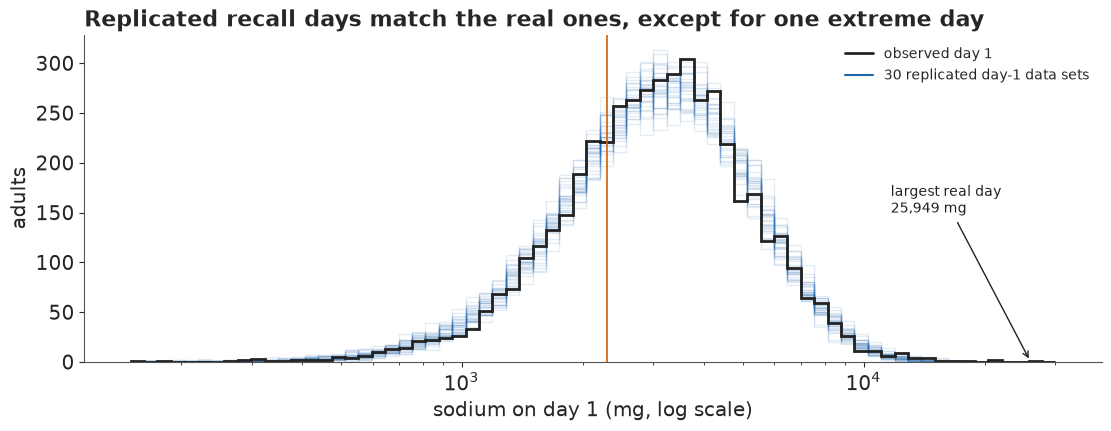

In [13]:
t0 = time.time()
th = idata.isel(draw=slice(None, None, 4))                       # 1,000 draws for derived quantities
X = lambda n: az.extract(th, var_names=[n]).values
A_, BC_, BP_, BR_ = X("a"), X("b_cell"), X("b_pir"), X("b_race")
SW_, SB_, GWK_, G2_, U_ = X("s_w").T, X("s_b").T, X("g_wk"), X("g_day2"), X("u").T   # (S, cell), (S,), (S, person)
MFIX = (A_ + BC_[CI] + BP_[PI] + BR_[RI]).T                                    # (S, person) fixed part
MU = MFIX + SB_[:, CI] * U_
S = MU.shape[0]
r1 = np.random.default_rng(2)
k_rep = r1.choice(S, 200, replace=False)
wk1 = d1.weekend.to_numpy() - 3 / 7
rep = ginv(MU[k_rep][:, p1] + GWK_[k_rep, None] * wk1 + SW_[k_rep][:, CI[p1]] * r1.standard_normal((200, len(p1))))
rows = []
for qq in [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]:
    lo_, hi_ = np.quantile(np.quantile(rep, qq, axis=1), [0.05, 0.95])
    rows.append((f"{qq:.0%}", np.quantile(x1, qq), lo_, hi_))
ppc = pd.DataFrame(rows, columns=["quantile", "observed", "rep 5%", "rep 95%"]).round(0)
print(ppc.to_string(index=False))
print(f"largest day: observed {x1.max():,.0f} mg; replicated maxima 5-95%: "
      f"{np.quantile(rep.max(1), 0.05):,.0f}-{np.quantile(rep.max(1), 0.95):,.0f} mg")
print(f"unweighted share over the line: observed {(x1 > LINE).mean():.3f}, replicated "
      f"{np.quantile((rep > LINE).mean(1), 0.05):.3f}-{np.quantile((rep > LINE).mean(1), 0.95):.3f}")

fig, ax = plt.subplots(figsize=(11, 4.2))
bins = np.geomspace(150, 30000, 70)
for k in range(30):
    h, _ = np.histogram(rep[k], bins=bins)
    ax.stairs(h, bins, color=HI, alpha=0.12)
ax.stairs(np.histogram(x1, bins=bins)[0], bins, color=INK, lw=2, label="observed day 1")
ax.plot([], [], color=HI, label="30 replicated day-1 data sets")
ax.axvline(LINE, color=LO, lw=1.2)
ax.annotate(f"largest real day\n{x1.max():,.0f} mg", (x1.max(), 1), xytext=(x1.max() * 0.45, 150),
            fontsize=10, color=INK, arrowprops=dict(arrowstyle="->", color=INK))
ax.set_xscale("log"); ax.set_xlabel("sodium on day 1 (mg, log scale)"); ax.set_ylabel("adults")
ax.legend(frameon=False, fontsize=10)
ax.set_title("Replicated recall days match the real ones, except for one extreme day", loc="left");
TIMES["ppc"] = time.time() - t0

The quantiles from the 1st to the 99th fall inside or at the edge of the replicated ranges (the
5th percentile, 1,176 mg, sits just above its replicated range, so the model puts slightly too
many people on very light days), and so does the share over the line. One real day does not:
someone reported 25,949 mg, beyond the largest of every replicated data set. One extreme day among
4,862 hardly moves a usual-intake distribution, but it is a reminder that the normal day error is
a choice; a Student-t day error is the first exercise.

This check has a blind spot, and part E will show why: day-1 values alone say nothing about how
their variance splits into person and day, which is exactly what moves the headline. A check of
the split has to look at the two days together. For the 4,239 people with two recalls we simulate
*fresh* people with the same covariates and weekdays, two days each, and compare the correlation
between the days, the spread of the day-2 minus day-1 difference, and whether that difference is
larger for people who eat more (the model assumes a constant day-to-day sd in each cell on this
scale; changing within-person spread is what the ISU method's second transformation handles).

In [14]:
t0 = time.time()
cnt2 = d.groupby("p").day.transform("count").to_numpy() == 2
ra, rb = d[cnt2 & (d.day == 1)].sort_values("p"), d[cnt2 & (d.day == 2)].sort_values("p")
pp2 = ra.p.to_numpy()
assert (pp2 == rb.p.to_numpy()).all()
YA, YB = Y[ra.index.to_numpy()], Y[rb.index.to_numpy()]
wka, wkb = ra.weekend.to_numpy() - 3 / 7, rb.weekend.to_numpy() - 3 / 7


def pair_stats(a, b):
    """Correlation of the two days, quantiles of b - a, and mean |b - a| by quintile of (a + b) / 2."""
    df, mid = b - a, (a + b) / 2
    bin_ = np.searchsorted(np.quantile(mid, [0.2, 0.4, 0.6, 0.8]), mid)
    return [np.corrcoef(a, b)[0, 1], *np.quantile(df, [0.05, 0.25, 0.75, 0.95]),
            *[np.abs(df[bin_ == j]).mean() for j in range(5)]]


r3 = np.random.default_rng(12)
reps2 = []
for k in r3.choice(S, 200, replace=False):
    mu_f = MFIX[k, pp2] + SB_[k, CI[pp2]] * r3.standard_normal(len(pp2))       # a fresh person
    sw_f = SW_[k, CI[pp2]]
    reps2.append(pair_stats(mu_f + GWK_[k] * wka + sw_f * r3.standard_normal(len(pp2)),
                            mu_f + G2_[k] + GWK_[k] * wkb + sw_f * r3.standard_normal(len(pp2))))
reps2 = np.array(reps2)
lab2 = (["day 1 - day 2 correlation"] + [f"difference, {v}th pct" for v in (5, 25, 75, 95)]
        + [f"mean |difference|, intake quintile {j + 1}" for j in range(5)])
print(pd.DataFrame({"observed": pair_stats(YA, YB), "rep 5%": np.quantile(reps2, 0.05, 0),
                    "rep median": np.median(reps2, 0), "rep 95%": np.quantile(reps2, 0.95, 0)},
                   index=lab2).round(3).to_string())
y_line = ((LINE**LAM - 1) / LAM - M0) / S0
print(f"2,300 mg sits at the {np.mean((YA + YB) / 2 < y_line):.0%} point of the two-day averages "
      f"(intake quintile 1 is below {np.quantile((YA + YB) / 2, 0.2):.2f}, the line at {y_line:.2f})")
TIMES["ppc_pairs"] = time.time() - t0

                                      observed  rep 5%  rep median  rep 95%
day 1 - day 2 correlation                0.400   0.375       0.404    0.432
difference, 5th pct                     -1.939  -1.997      -1.925   -1.863
difference, 25th pct                    -0.821  -0.929      -0.879   -0.832
difference, 75th pct                     0.491   0.498       0.550    0.598
difference, 95th pct                     1.514   1.510       1.592    1.670
mean |difference|, intake quintile 1     0.840   0.789       0.833    0.866
mean |difference|, intake quintile 2     0.782   0.808       0.844    0.884
mean |difference|, intake quintile 3     0.772   0.822       0.856    0.892
mean |difference|, intake quintile 4     0.816   0.833       0.871    0.910
mean |difference|, intake quintile 5     0.927   0.865       0.908    0.947
2,300 mg sits at the 29% point of the two-day averages (intake quintile 1 is below -0.76, the line at -0.53)


The part that matters most passes. The correlation between a person's two days, which is the
between-person share of the variance, is reproduced, and so are the 5th and 95th percentiles of
the day-to-day difference. Two things are not. The central half of the real differences is
narrower than the model's (the observed 25th and 75th percentiles, -0.82 and +0.49, fall just
short of the replicated ranges), with the same outer tails: real day-to-day changes are more
often small and occasionally large, the heavier tails the Box-Cox kurtosis already showed. And
the real differences are smaller in the middle three intake quintiles (0.77-0.82) than at the
ends (0.84 and 0.93), and in those middle three they fall below the model's whole replicated
range; the model's own curve rises only gently, from about 0.83 to 0.91. Both point to the
Student-t day error of the first exercise, and to a day-to-day spread that varies with intake.
The second matters for the headline more than it first seems, because the line is not in the
middle of the distribution: 2,300 mg sits near the 14th percentile of usual intake, the 26th of
single days and the 29th of the two-day averages, inside the second quintile, where real
day-to-day changes are *smaller* than the model assumes (0.78 against 0.84). A spread that
changes with intake shifts a deconvolved share near the line by an amount, and in a direction,
that this model cannot tell us; it joins the caveats at the end.

## D · What changes, and for whom?

### The share over the line

The population share over the line is a property of usual intakes across the US adult population,
not of the 4,863 people who happened to be sampled. For each posterior draw we give every sampled
adult a *fresh* person effect $u \sim N(0,1)$ around their covariates, compute that new person's
usual intake, and average with the survey weights. This is a weighted post-stratification over
the sample's covariate mix. For comparison we also use the sampled people's own posterior usual
intakes, and the shortcut that back-transforms $\mu_i$ directly, which gives a person's *median*
day instead of their mean.

In [15]:
GH_X, GH_W = np.polynomial.hermite_e.hermegauss(24)
GH_W = GH_W / GH_W.sum()


def usual(mu, sw, gwk):
    """Usual intake (mg): mean over day noise (Gauss-Hermite) and a typical week; arrays (S, person)."""
    out = 0.0
    for wkv, wt in ((-3 / 7, 4 / 7), (4 / 7, 3 / 7)):
        out = out + wt * (ginv((mu + gwk * wkv)[..., None] + sw[..., None] * GH_X) * GH_W).sum(-1)
    return out


def chunked(fn, *arrs, step=100):
    return np.concatenate([fn(*(a[k:k + step] for a in arrs)) for k in range(0, arrs[0].shape[0], step)])


r2 = np.random.default_rng(3)
MU_NEW = MFIX + SB_[:, CI] * r2.standard_normal(MFIX.shape)          # fresh people, same covariates
SWP = SW_[:, CI]
T_SAMPLED = chunked(usual, MU, SWP, np.repeat(GWK_[:, None], N, 1))
T_NEW = chunked(usual, MU_NEW, SWP, np.repeat(GWK_[:, None], N, 1))
T_MEDIAN_DAY = ginv(MU_NEW)
share = lambda T, f=lambda v: v > LINE, m=slice(None): (f(T[:, m]) * W[m]).sum(1) / W[m].sum()
USUAL = share(T_NEW)
P_HIGHER = (USUAL > ONE_DAY).mean()
print(f"one-day share over the line (weighted):          {ONE_DAY:.3f}")
print(f"usual intake, fresh people (population):         {q(USUAL)}   P(usual > one-day) = {P_HIGHER:.3f}")
print(f"usual intake, the sampled people:                {q(share(T_SAMPLED))}")
print(f"'median day' back-transform, fresh people:       {q(share(T_MEDIAN_DAY))}")
print("weighted 5/50/95 percentiles of usual intake (mg):",
      np.median([wquant(t, W, [0.05, 0.5, 0.95]) for t in T_NEW[:200]], axis=0).round(-1))
TIMES["derived"] = time.time() - t0
del idata, th, U_, MU_NEW                   # derived arrays are all we need from here

one-day share over the line (weighted):          0.740
usual intake, fresh people (population):         [0.85 0.86 0.88]   P(usual > one-day) = 1.000
usual intake, the sampled people:                [0.86 0.87 0.88]
'median day' back-transform, fresh people:       [0.8  0.82 0.84]
weighted 5/50/95 percentiles of usual intake (mg): [1890. 3360. 5680.]


**About 86% of US adults (89% interval 85-88%) usually eat more than 2,300 mg of sodium**, against
74% judged by one day. In every one of the 1,000 posterior draws the usual-intake share is higher
than the one-day share. The usual-intake median is about 3,400 mg and the middle 90% of adults sit
between about 1,900 and 5,700 mg, a much narrower range than the 1,200-7,000 mg of single days.
The sampled people's own usual intakes give almost the same share (87%); the fresh-person version
is the population estimate, and slightly wider, because it does not lean on the particular 4,863
people.

The back-transform is not a detail. Using each person's median day, $g^{-1}(\mu_i)$, instead of
their mean day gives 82%. A naive analysis that models on a transformed scale and then reports
$g^{-1}$ of the fitted level understates everyone's intake, because a skewed day distribution has
a mean above its median.

### Three lines, two directions

The direction of the one-day error depends on where the line sits, exactly as in the toy. Here are
the lower limit sometimes quoted for people with high blood pressure (1,500 mg), the guideline
(2,300 mg), and a heavy-intake mark (5,000 mg).

share of adults  one day  usual  usual 5.5%  usual 94.5%
 under 1,500 mg    0.091  0.012       0.008        0.018
  over 2,300 mg    0.740  0.864       0.847        0.880
  over 5,000 mg    0.174  0.111       0.096        0.126


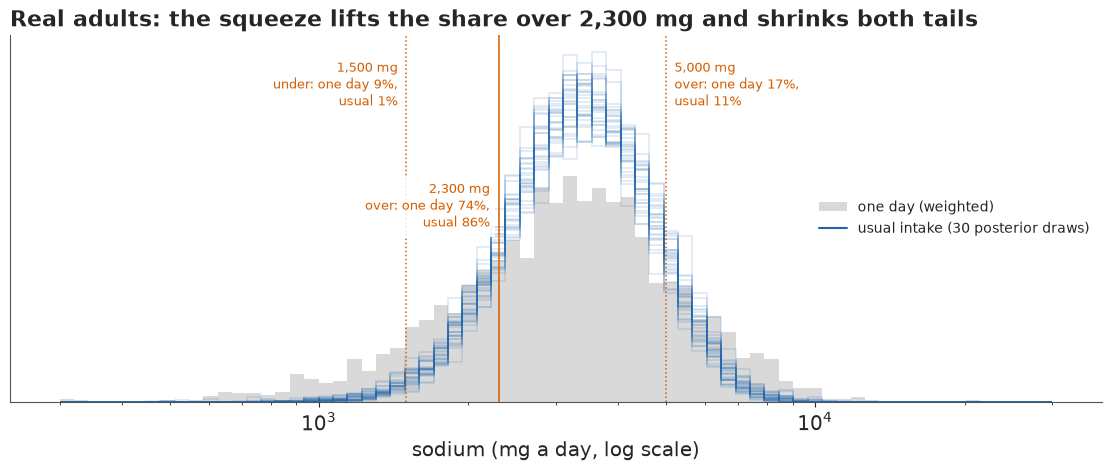

In [16]:
rows = []
for lab, f in [("under 1,500 mg", lambda v: v < 1500), ("over 2,300 mg", lambda v: v > LINE),
               ("over 5,000 mg", lambda v: v > 5000)]:
    us = share(T_NEW, f)
    rows.append((lab, np.average(f(x1), weights=w1), np.median(us), np.quantile(us, 0.055), np.quantile(us, 0.945)))
print(pd.DataFrame(rows, columns=["share of adults", "one day", "usual", "usual 5.5%", "usual 94.5%"]
                   ).round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 4.6))
bins = np.geomspace(300, 30000, 70)
ax.hist(x1, bins=bins, weights=w1, color=LIGHT, label="one day (weighted)")
for k in range(30):
    h, _ = np.histogram(T_NEW[k], bins=bins, weights=W)
    ax.stairs(h, bins, color=HI, alpha=0.15, lw=1.2)
ax.plot([], [], color=HI, label="usual intake (30 posterior draws)")
ymax = ax.get_ylim()[1]
for v, t, (od, us), (ha, yy) in zip((1500, LINE, 5000), ("1,500", "2,300", "5,000"),
                                    [(r[1], r[2]) for r in rows], [("right", 0.93), ("right", 0.6), ("left", 0.93)]):
    ax.axvline(v, color=LO, lw=1.1, ls="-" if v == LINE else ":")
    side = "under" if v == 1500 else "over"
    ax.text(v * (0.96 if ha == "right" else 1.04), ymax * yy, f"{t} mg\n{side}: one day {od:.0%},\nusual {us:.0%}",
            color=LO, fontsize=9.5, va="top", ha=ha, bbox=dict(fc="white", ec="none", alpha=0.85))
ax.set_xscale("log"); ax.set_yticks([])
ax.set_xlabel("sodium (mg a day, log scale)")
ax.legend(loc="center right", fontsize=10, frameon=False)
ax.set_title("Real adults: the squeeze lifts the share over 2,300 mg and shrinks both tails", loc="left");

Under 1,500 mg, the one-day share is 9% and the usual share about 1%: almost nobody *usually* eats
that little, though many people have a light day. Over 5,000 mg, one day says 17% and the usual
intake about 11%. Over 2,300 mg, the error flips sign. A rule of thumb follows: a single day
exaggerates how many people are in a tail and understates how many are on the side of the line
where the middle lies.

The tail shares depend more on the model than the headline does. To see how much, we refit the
same model on the plain log scale, where the usual intake has the closed form
$E[x\mid\mu_i] = \exp(\mu_i + \sigma_w^2/2)$ (with $\mu_i$ and $\sigma_w$ on the log scale).

In [17]:
t0 = time.time()
LX = np.log(x_all)
LM, LS = LX[d.day.to_numpy() == 1].mean(), LX[d.day.to_numpy() == 1].std()
with sodium_model(y=(LX - LM) / LS):
    idata_log = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
tl = idata_log.isel(draw=slice(None, None, 4))
XL = lambda n: az.extract(tl, var_names=[n]).values
mu_l = ((XL("a") + XL("b_cell")[CI] + XL("b_pir")[PI] + XL("b_race")[RI]).T
        + XL("s_b").T[:, CI] * np.random.default_rng(13).standard_normal((S, N)))
sw_l, gw_l = XL("s_w").T[:, CI], XL("g_wk")[:, None]
T_LOG = sum(wt * np.exp(LM + LS * (mu_l + gw_l * wkv) + (LS * sw_l) ** 2 / 2)
            for wkv, wt in ((-3 / 7, 4 / 7), (4 / 7, 3 / 7)))
print(f"log scale: divergences {int(idata_log.sample_stats['diverging'].sum())}, "
      f"max r_hat (s_w, s_b) {max(float(az.rhat(idata_log, var_names=[v]).to_dataset()[v].max()) for v in ['s_w', 's_b']):.3f}")
for lab, f in [("under 1,500 mg", lambda v: v < 1500), ("over 2,300 mg", lambda v: v > LINE),
               ("over 5,000 mg", lambda v: v > 5000)]:
    print(f"{lab:15s} Box-Cox {q(share(T_NEW, f))}   log {q(share(T_LOG, f))}")
del idata_log, tl, mu_l, sw_l, T_LOG
TIMES["fit_log"] = time.time() - t0

log scale: divergences 0, max r_hat (s_w, s_b) 1.004
under 1,500 mg  Box-Cox [0.01 0.01 0.02]   log [0.01 0.01 0.02]
over 2,300 mg   Box-Cox [0.85 0.86 0.88]   log [0.84 0.85 0.87]
over 5,000 mg   Box-Cox [0.1  0.11 0.13]   log [0.13 0.14 0.16]


The headline hardly cares about the scale, but the share over 5,000 mg rises from about 11% to
about 14% on the log scale, whose heavier upper tail goes with its left-skewed days. The
transformation is a modelling choice that matters most in the tails.

### Sex and income

Jackson et al. (2016) found 98% of men and 80% of women over the line in 2009-2012. And the
one-day shares differed by 11 points between the poorest and the richest income bands. Does that
gap survive once the noise is gone?

In [18]:
male = (per.sex == "male").to_numpy()
for lab, m in (("men", male), ("women", ~male)):
    mm = m[p1]
    print(f"{lab:6s} one-day {np.average(x1[mm] > LINE, weights=w1[mm]):.3f}   usual {q(share(T_NEW, m=m))}")
BAND = {}
for j, lab in enumerate(PIR_LAB):
    m = PI == j
    mm = m[p1]
    BAND[lab] = (np.average(x1[mm] > LINE, weights=w1[mm]), share(T_NEW, m=m))
    print(f"income {lab:8s} n={m.sum():5d}  one-day {BAND[lab][0]:.3f}   usual {q(BAND[lab][1])}")
gap_one = BAND["4+"][0] - BAND["<1"][0]
gap = BAND["4+"][1] - BAND["<1"][1]
P_GAP = (gap > 0).mean()
print(f"gap 4+ minus <1: one day {gap_one:+.3f}; usual {q(gap)}; P(poorest band lower) = {P_GAP:.3f}")

# can the model reproduce the observed one-day shares? one simulated recall day per fresh person
r4 = np.random.default_rng(14)
wk1 = d1.weekend.to_numpy() - 3 / 7
rep1 = []
for k in range(0, S, 5):
    o_ = ginv(MFIX[k, p1] + SB_[k, CI[p1]] * r4.standard_normal(len(p1)) + GWK_[k] * wk1
              + SW_[k, CI[p1]] * r4.standard_normal(len(p1))) > LINE
    rep1.append([o_.mean(), np.average(o_, weights=w1)]
                + [np.average(o_[PI[p1] == j], weights=w1[PI[p1] == j]) for j in (0, 4)]
                + [o_[PI[p1] == j].mean() for j in (0, 4)])
rep1 = np.array(rep1)
gap_one_uw = (x1[PI[p1] == 4] > LINE).mean() - (x1[PI[p1] == 0] > LINE).mean()
print(f"one-day share, fresh people: unweighted {q(rep1[:, 0])} (observed {(x1 > LINE).mean():.3f}); "
      f"weighted {q(rep1[:, 1])} (observed {ONE_DAY:.3f})")
print(f"one-day gap 4+ minus <1, fresh people: weighted {q(rep1[:, 3] - rep1[:, 2])} (observed {gap_one:+.3f}); "
      f"unweighted {q(rep1[:, 5] - rep1[:, 4])} (observed {gap_one_uw:+.3f})")
print("two-day method of moments on the model scale (unadjusted):",
      {lab: (round(float(np.var((YB - YA)[PI[pp2] == j]) / 2), 2),
             round(float(np.cov(YA[PI[pp2] == j], YB[PI[pp2] == j])[0, 1]), 2)) for j, lab in enumerate(PIR_LAB[:5])},
      "(within, between)")
print("share of adults under 31, by income band:",
      {lab: round(float(np.average(per.age.to_numpy()[PI == j] < 31, weights=W[PI == j])), 2)
       for j, lab in enumerate(PIR_LAB[:5])})

men    one-day 0.831   usual [0.94 0.95 0.96]
women  one-day 0.655   usual [0.75 0.78 0.81]
income <1       n=  810  one-day 0.668   usual [0.79 0.83 0.86]
income 1-2      n= 1196  one-day 0.695   usual [0.82 0.85 0.88]
income 2-3      n=  709  one-day 0.755   usual [0.84 0.88 0.91]
income 3-4      n=  468  one-day 0.779   usual [0.84 0.88 0.92]
income 4+       n= 1108  one-day 0.783   usual [0.85 0.88 0.91]
income unknown  n=  572  one-day 0.696   usual [0.77 0.82 0.87]
gap 4+ minus <1: one day +0.115; usual [0.01 0.06 0.1 ]; P(poorest band lower) = 0.989
one-day share, fresh people: unweighted [0.69 0.7  0.71] (observed 0.708); weighted [0.7  0.71 0.74] (observed 0.740)
one-day gap 4+ minus <1, fresh people: weighted [0.02 0.06 0.11] (observed +0.115); unweighted [0.03 0.06 0.1 ] (observed +0.099)
two-day method of moments on the model scale (unadjusted): {'<1': (0.7, 0.46), '1-2': (0.55, 0.4), '2-3': (0.64, 0.31), '3-4': (0.53, 0.31), '4+': (0.46, 0.36)} (within, between)
share of a

By sex the picture has the 2009-2012 shape: 95% of men and 78% of women are usually over the line
(98% and 80% then), against 83% and 66% on one day. By income, the usual-intake shares are all
in the 80s, from about 83% below the poverty line to about 88% at twice it and above. The usual
gap between the poorest and the richest band is about 6 points (89% interval 1-10), and it is
*very likely* (98.9%) that the poorest band is usually over less often.

It is tempting to say the gap shrank from 11 points to 6 because noise was removed. The replicated
recall days say otherwise. Simulated one-day recalls for fresh people with the same covariates
reproduce the unweighted one-day share (70% against 71%) but come out at about 71% weighted
(70-74%), against the observed 74%. Their one-day income gap is about 6 points (2-11 weighted,
3-10 unweighted), against an observed 10 points unweighted and 11.5 weighted. So the weights
explain only a small part of the shortfall; most of it is the model. This model understates the
income gap, and its usual-intake 6 points is best read as a low-leaning estimate whose direction
is solid and whose size is not: from it alone we cannot tell whether the usual gap is smaller
than the one-day gap at all. The same misfit leaves the weighted one-day share about 3 points low,
so the population headline may be a point or two low too.

Two features of the model are candidates. Its income effect is additive, the same on top of every
age, sex and race group, with no interactions. And its variance split is shared across income
bands, although the poorest band is younger (32% under 31, against 14% in the richest), and the
unadjusted two-day moments give it more spread both within people (0.70 against 0.46 on the
model's scale) and between them (0.46 against 0.36). Part E lets the split vary by income and
checks whether that reproduces the one-day gap. Income bands differ in their age, sex and race
mix, so these are differences between groups as they are, not effects of income.

## E · What does the second day buy?

### Integrating the person out

Everything above rests on the second recall. To see that directly we rewrite the model so that the
person effects are integrated out, which leaves only the quantities a replicate can inform. Let
$s_c$ be the total one-day sd in cell $c$ and $f$ the share of one-day variance that is
within-person, so $\sigma_w^2 = f s^2$ and $\sigma_b^2 = (1-f)s^2$. Write $r_{ij}$ for the
residual of day $j$ after the covariates and day effects. For a person with one recall,

$$r_{i1} \sim N(0,\ \sigma_b^2 + \sigma_w^2) = N(0,\ s^2),$$

and $f$ does not appear at all. For a person with two recalls, the half-sum and the difference
are independent normals,

$$\tfrac12(r_{i1}+r_{i2}) \sim N\big(0,\ \sigma_b^2 + \tfrac12\sigma_w^2\big),\qquad
r_{i2}-r_{i1} \sim N(0,\ 2\sigma_w^2),$$

and the difference speaks to $\sigma_w$ alone. With only first days, the likelihood is flat in
$f$, and its posterior must be exactly its prior, $f \sim \text{Beta}(4, 3)$. The marginal model
has no 4,863 person effects, so it samples quickly, and the usual-intake share still follows from
each draw by simulating fresh people.

prior f 89% interval: [0.28 0.58 0.84]


both days               4239 people with 2 days  divergences 0  max r_hat 1.003  f [0.63 0.65 0.67]  share over line [0.84 0.86 0.88]


day 1 only                 0 people with 2 days  divergences 0  max r_hat 1.003  f [0.28 0.58 0.84]  share over line [0.76 0.84 0.93]


300 second days          300 people with 2 days  divergences 0  max r_hat 1.002  f [0.62 0.69 0.76]  share over line [0.84 0.87 0.9 ]


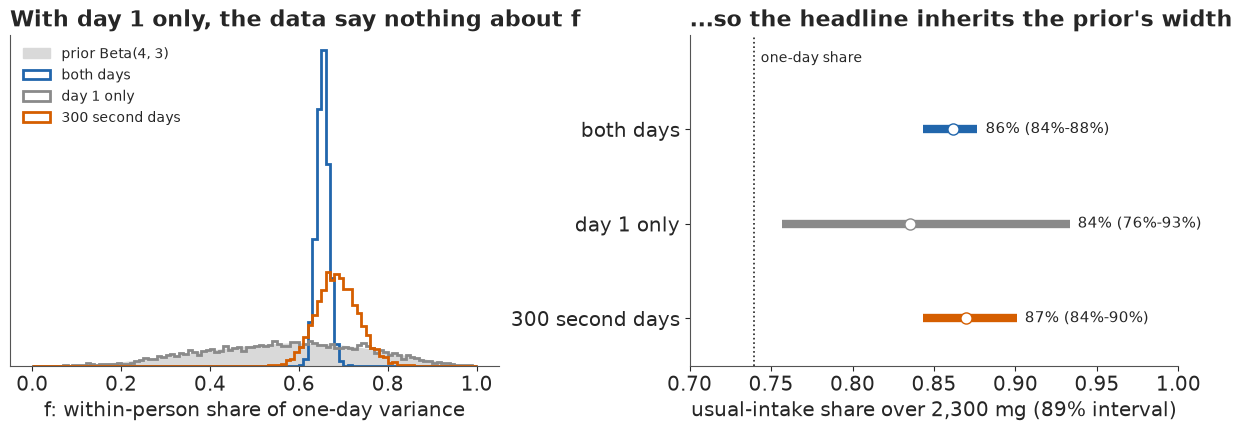

In [19]:
def marginal_fit(dd, label):
    """Person effects integrated out; dd holds the recall rows to use."""
    cnt = dd.groupby("p").day.transform("count").to_numpy()
    one = dd[cnt == 1]
    two = dd[cnt == 2].sort_values(["p", "day"])
    t1, t2 = two[two.day == 1], two[two.day == 2]
    assert (t1.p.to_numpy() == t2.p.to_numpy()).all()

    def parts(rows):
        return (rows.p.to_numpy(), (rows.day.to_numpy() == 2) * 1.0, rows.weekend.to_numpy() - 3 / 7,
                Y[rows.index.to_numpy()])

    with pm.Model(coords=COORDS) as m:
        a = pm.Normal("a", 0, 1)
        bc = pm.ZeroSumNormal("b_cell", 0.5, dims="cell")
        bp = pm.ZeroSumNormal("b_pir", 0.5, dims="pir")
        br = pm.ZeroSumNormal("b_race", 0.5, dims="race")
        g2, gw = pm.Normal("g_day2", 0, 0.5), pm.Normal("g_wk", 0, 0.5)
        s_tot = pm.LogNormal("s_tot", 0, 0.3, dims="cell")
        f = pm.Beta("f", 4, 3)
        fix = a + bc[CI] + bp[PI] + br[RI]
        mean = lambda pp, dd2, ww: fix[pp] + g2 * dd2 + gw * ww
        po, do, wo, yo = parts(one)
        pm.Normal("y_one", mean(po, do, wo), s_tot[CI[po]], observed=yo)
        if len(t1):
            pa, da, wa, ya = parts(t1)
            pb_, db, wb, yb = parts(t2)
            st = s_tot[CI[pa]]
            pm.Normal("half_sum", (mean(pa, da, wa) + mean(pb_, db, wb)) / 2,
                      st * pt.sqrt(1 - f + f / 2), observed=(ya + yb) / 2)
            pm.Normal("diff", mean(pb_, db, wb) - mean(pa, da, wa), st * pt.sqrt(2 * f), observed=yb - ya)
        idm = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
    rh = max(float(az.rhat(idm, var_names=[v]).to_dataset()[v].max()) for v in ["a", "s_tot", "f", "b_pir"])
    fq = idm.posterior["f"].values.ravel()
    # usual-intake share from fresh people, 1,000 draws
    tk = idm.isel(draw=slice(None, None, 4))
    Z = lambda n: az.extract(tk, var_names=[n]).values
    fx = (Z("a") + Z("b_cell")[CI] + Z("b_pir")[PI] + Z("b_race")[RI]).T
    st, ff, gwk = Z("s_tot").T[:, CI], Z("f"), Z("g_wk")
    mu_new = fx + st * np.sqrt(1 - ff)[:, None] * np.random.default_rng(4).standard_normal(fx.shape)
    Tn = chunked(usual, mu_new, st * np.sqrt(ff)[:, None], np.repeat(gwk[:, None], N, 1))
    sh = share(Tn)
    print(f"{label:22s} {len(t1):5d} people with 2 days  divergences {int(idm.sample_stats['diverging'].sum())}  "
          f"max r_hat {rh:.3f}  f {np.round(np.quantile(fq, [0.055, 0.5, 0.945]), 2)}  "
          f"share over line {np.round(np.quantile(sh, [0.055, 0.5, 0.945]), 2)}")
    return fq, sh


t0 = time.time()
print("prior f 89% interval:", np.round(stats.beta(4, 3).ppf([0.055, 0.5, 0.945]), 2))
r5 = np.random.default_rng(5)
two_ids = d.groupby("p").day.count()
keep300 = r5.choice(two_ids.index[two_ids == 2].to_numpy(), 300, replace=False)
FITS = {"both days": marginal_fit(d, "both days"),
        "day 1 only": marginal_fit(d[d.day == 1], "day 1 only"),
        "300 second days": marginal_fit(d[(d.day == 1) | d.p.isin(keep300)], "300 second days")}
TIMES["part_E"] = time.time() - t0

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
grid = np.linspace(0, 1, 300)
axs[0].fill_between(grid, stats.beta(4, 3).pdf(grid), color=LIGHT, label="prior Beta(4, 3)")
for (lab, (fq, _)), col in zip(FITS.items(), (HI, MUTED, LO)):
    axs[0].hist(fq, bins=np.linspace(0, 1, 101), density=True, histtype="step", lw=2, color=col, label=lab)
axs[0].set_xlabel("f: within-person share of one-day variance"); axs[0].set_yticks([])
axs[0].legend(frameon=False, fontsize=10)
axs[0].set_title("With day 1 only, the data say nothing about f", loc="left")
for i, ((lab, (_, sh)), col) in enumerate(zip(FITS.items(), (HI, MUTED, LO))):
    lo_, md_, hi_ = np.quantile(sh, [0.055, 0.5, 0.945])
    axs[1].plot([lo_, hi_], [i, i], color=col, lw=6, solid_capstyle="butt")
    axs[1].plot([md_], [i], "o", color="white", mec=col, ms=8)
    axs[1].text(hi_ + 0.005, i, f"{md_:.0%} ({lo_:.0%}-{hi_:.0%})", va="center", fontsize=10.5)
axs[1].axvline(ONE_DAY, color=INK, ls=":", lw=1.2)
axs[1].text(ONE_DAY + 0.004, -0.75, "one-day share", fontsize=10, ha="left", va="center")
axs[1].set_yticks(range(3), list(FITS)); axs[1].set_ylim(2.5, -1.0)
axs[1].set_xlim(0.7, 1.0); axs[1].set_xlabel("usual-intake share over 2,300 mg (89% interval)")
axs[1].set_title("...so the headline inherits the prior's width", loc="left");

With both days, $f \approx 0.65$ (0.63-0.67): about two thirds of a day's variance on this scale
is day-to-day noise, consistent with the full model, and the share is 86% (84-88%) as before. With
the first day only, the posterior of $f$ is the Beta(4, 3) prior, as the algebra says, and the
usual-intake share inherits it: 84% with an interval from 76% to 93%, depending on how much of the
spread we *assume* is noise. A survey with one recall per person can only report the one-day
distribution, or borrow $f$ from somewhere else (the NCI method allows this, from an external
replicate study). The surprise is how little it takes. With only 300 second days among 4,863
people, the interval for $f$ shrinks from the prior's 0.28-0.84 to 0.62-0.76 and the share comes
out at 87% (84-90%), close to the full answer: a small replicate sample identifies the variance
split for everyone.

The latent-person form of the same model hides this less gracefully. In trial runs not repeated
here (seed 108, nutpie's default 4 x 1,000 draws), fitting the day-1-only data with all 4,863
person effects and the $(s, f)$ parameterisation gave zero divergences but $\hat R = 1.41$ and
an effective sample size of 8 for $f$, and `sodium_model` on day 1 only gave $\hat R \approx 2$
on every scale: each chain wandered along the prior while dragging every $u_i$ with it.
Integrated out, the same non-identification is exact and samples cleanly. When a sampler struggles
on a parameter that should be well defined, it is worth asking whether the data speak to it at
all.

### A check on the income gap

The marginal form makes the check part D promised cheap. We let both the total one-day sd and the
within-person share $f$ vary by income band as well as by cell: $s = s_c\,e^{k_{\text{income}}}$
and $\operatorname{logit} f = \ell_0 + \ell_c + \ell_{\text{income}}$, with zero-sum effects.

In [20]:
t0 = time.time()
with pm.Model(coords=COORDS) as m_inc:
    a = pm.Normal("a", 0, 1)
    bc, bp = pm.ZeroSumNormal("b_cell", 0.5, dims="cell"), pm.ZeroSumNormal("b_pir", 0.5, dims="pir")
    br = pm.ZeroSumNormal("b_race", 0.5, dims="race")
    g2, gw = pm.Normal("g_day2", 0, 0.5), pm.Normal("g_wk", 0, 0.5)
    s_c, k_pir = pm.LogNormal("s_tot", 0, 0.3, dims="cell"), pm.ZeroSumNormal("k_pir", 0.3, dims="pir")
    lf0, lf_c = pm.Normal("lf0", np.log(4 / 3), 1.0), pm.ZeroSumNormal("lf_cell", 0.5, dims="cell")
    lf_p = pm.ZeroSumNormal("lf_pir", 0.5, dims="pir")
    sP = s_c[CI] * pt.exp(k_pir[PI])                                    # per person
    fP = pm.math.sigmoid(lf0 + lf_c[CI] + lf_p[PI])
    fix = a + bc[CI] + bp[PI] + br[RI]
    one_ = d[~d.p.isin(pp2)]
    po_ = one_.p.to_numpy()
    pm.Normal("y_one", fix[po_] + g2 * (one_.day.to_numpy() == 2) + gw * (one_.weekend.to_numpy() - 3 / 7),
              sP[po_], observed=Y[one_.index.to_numpy()])
    ma, mb = fix[pp2] + gw * wka, fix[pp2] + g2 + gw * wkb
    pm.Normal("half_sum", (ma + mb) / 2, sP[pp2] * pt.sqrt(1 - fP[pp2] / 2), observed=(YA + YB) / 2)
    pm.Normal("diff", mb - ma, sP[pp2] * pt.sqrt(2 * fP[pp2]), observed=YB - YA)
    idm = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
print(f"divergences {int(idm.sample_stats['diverging'].sum())}, max r_hat "
      f"{max(float(az.rhat(idm, var_names=[v]).to_dataset()[v].max()) for v in ['a', 's_tot', 'k_pir', 'lf_pir', 'lf_cell', 'b_pir']):.3f}")
tk = idm.isel(draw=slice(None, None, 4))
Z = lambda n: az.extract(tk, var_names=[n]).values
sPd = (Z("s_tot")[CI] * np.exp(Z("k_pir")[PI])).T
fPd = 1 / (1 + np.exp(-(Z("lf0") + Z("lf_cell")[CI] + Z("lf_pir")[PI]).T))
print(pd.DataFrame({"within sd": [np.median((sPd * np.sqrt(fPd))[:, PI == j]) for j in range(6)],
                    "between sd": [np.median((sPd * np.sqrt(1 - fPd))[:, PI == j]) for j in range(6)]},
                   index=PIR_LAB).round(2).T.to_string())
mu_i = ((Z("a") + Z("b_cell")[CI] + Z("b_pir")[PI] + Z("b_race")[RI]).T
        + sPd * np.sqrt(1 - fPd) * np.random.default_rng(15).standard_normal((S, N)))
T_INC = chunked(usual, mu_i, sPd * np.sqrt(fPd), np.repeat(Z("g_wk")[:, None], N, 1))
gap_inc = share(T_INC, m=PI == 4) - share(T_INC, m=PI == 0)
print(f"all adults {q(share(T_INC))}; poorest {q(share(T_INC, m=PI == 0))}; richest {q(share(T_INC, m=PI == 4))}")
print(f"gap 4+ minus <1: {q(gap_inc)} (shared split: {q(gap)}); P(poorest lower) = {(gap_inc > 0).mean():.3f}")
# does this model reproduce the one-day income gap? one simulated recall day per fresh person
gwk_i, rep_inc = Z("g_wk"), []
for k in range(0, S, 5):
    o_ = ginv(mu_i[k, p1] + gwk_i[k] * wk1 + (sPd * np.sqrt(fPd))[k, p1] * r4.standard_normal(len(p1))) > LINE
    rep_inc.append([np.average(o_, weights=w1)]
                   + [np.average(o_[PI[p1] == j], weights=w1[PI[p1] == j]) for j in (0, 4)])
rep_inc = np.array(rep_inc)
print(f"one-day share, fresh people: weighted {q(rep_inc[:, 0])} (observed {ONE_DAY:.3f}); "
      f"one-day gap {q(rep_inc[:, 2] - rep_inc[:, 1])} (observed {gap_one:+.3f})")
del idm, tk, mu_i, T_INC, sPd, fPd
TIMES["fit_income"] = time.time() - t0

divergences 0, max r_hat 1.005


              <1   1-2   2-3   3-4    4+  unknown
within sd   0.85  0.74  0.80  0.75  0.69     0.77
between sd  0.60  0.56  0.52  0.49  0.52     0.54


all adults [0.85 0.87 0.89]; poorest [0.78 0.82 0.86]; richest [0.86 0.89 0.92]
gap 4+ minus <1: [0.02 0.07 0.12] (shared split: [0.01 0.06 0.1 ]); P(poorest lower) = 0.986


one-day share, fresh people: weighted [0.7  0.72 0.73] (observed 0.740); one-day gap [0.04 0.09 0.15] (observed +0.115)


The poorest band does have the most spread, both from day to day and between people, as the
moments suggested. More between-person spread around a mean above the line puts more of its people
usually under it, and the usual gap widens a little, to about 7 points (2-12), with the headline
about the same at 87% (85-89%). This model also does better at the test the first one failed: its
simulated single days give an income gap of about 9 points (4-15), with the observed 11.5 inside
that range, though its weighted one-day share, 72% (70-73%), is still short of 74%. So much of the
missing one-day gap came from forcing every band to share one variance split. With that fixed,
the usual gap (7) is a little smaller than the model's one-day gap (9), as noise removal would
suggest, but both intervals are wide and overlap; the direction is solid, the size is roughly 2 to
12 points.

## F · Alcohol: zeros that mean "not today"

Sodium is eaten every day. Alcohol is not: 77% of adults report no alcohol on a given recall day,
and a zero can mean "never drinks" or "did not drink today". A model of usual intake must say how
often and how much, and the two are related, since frequent drinkers also tend to drink more per
occasion. The NCI method (Tooze et al. 2006; Kipnis et al. 2009) uses a **correlated two-part
model**:

$$\Pr(\text{drink}_{ij}) = \operatorname{logit}^{-1}(x_i^\top\alpha + v_i + \text{day terms}),\qquad
\log \text{grams}_{ij}\mid\text{drink} \sim N(x_i^\top\delta + w_i + \text{day terms},\ \tau^2),$$
$$(v_i, w_i) \sim N\left(0,\ \begin{pmatrix}\sigma_v^2 & \rho\sigma_v\sigma_w \\ \rho\sigma_v\sigma_w & \sigma_w^2\end{pmatrix}\right),$$

and usual intake is $T_i = \Pr(\text{drink})\times E[\text{grams}\mid\text{drink}]$, averaged over
a typical week. Fitted in two separate stages, the parts cannot share their person effects; in
PyMC the correlation $\rho$ is one more parameter. For a 2 x 2 correlation an LKJ(2) prior is
exactly $(\rho + 1)/2 \sim \text{Beta}(2, 2)$.

Two days are thin evidence for how often someone drinks. The questionnaire helps: NHANES asks how
often each person drank in the past year. We use it twice. Adults who report no drink in the past
year and no alcohol on either recall day are treated as true zeros (the NCI method's "never
consumers"), and for everyone else the reported frequency enters both parts as a covariate.

In [21]:
FL = ["none past yr", "daily", "nearly daily", "3-4/wk", "2/wk", "1/wk", "2-3/mo", "1/mo", "7-11/yr",
      "3-6/yr", "1-2/yr", "missing"]
fq_all = per.alq_freq.to_numpy()
fcat_all = np.where(np.isnan(fq_all), 11, fq_all).astype(int)
anyd = d.groupby("p").alcohol_g.apply(lambda s: (s > 0).any()).reindex(range(N)).to_numpy()
structural = (fcat_all == 0) & ~anyd
alc1 = d1.alcohol_g.to_numpy()
print(f"recall days with any alcohol: {np.average(alc1 > 0, weights=w1):.1%} (weighted, day 1)")
print(f"past-year non-drinkers with no alcohol on the recalls (true zeros): {structural.sum():,}; "
      f"past-year non-drinkers who drank on a recall day: {((fcat_all == 0) & anyd).sum()}")
print(pd.DataFrame({"adults": pd.Series(fcat_all).value_counts().sort_index().to_numpy(),
                    "day-1 drink share": pd.Series(alc1 > 0).groupby(fcat_all[p1]).mean().reindex(range(12)).round(2).to_numpy()},
                   index=FL).T.to_string())

keep = np.flatnonzero(~structural)
da = d[d.p.isin(keep)].copy()
da["q"] = pd.Index(keep).get_indexer(da.p)
QP = da.q.to_numpy()
FI, CIa, PIa, RIa = fcat_all[keep], CI[keep], PI[keep], RI[keep]
alc = da.alcohol_g.to_numpy()
drank = (alc > 0).astype(int)
pos = drank == 1
WKa, D2a = da.weekend.to_numpy() - 3 / 7, (da.day.to_numpy() == 2) * 1.0
la = np.log(alc[pos])
AM0, AS0 = la.mean(), la.std()
print(f"hurdle on {len(keep):,} adults, {len(da):,} days, {pos.sum():,} drinking days; "
      f"median drinking-day amount {np.exp(np.median(la)):.0f} g")

recall days with any alcohol: 23.4% (weighted, day 1)
past-year non-drinkers with no alcohol on the recalls (true zeros): 1,442; past-year non-drinkers who drank on a recall day: 23
                   none past yr   daily  nearly daily  3-4/wk    2/wk    1/wk  2-3/mo    1/mo  7-11/yr  3-6/yr  1-2/yr  missing
adults                  1465.00  133.00        145.00  262.00  299.00  318.00  557.00  323.00   284.00  437.00  483.00   157.00
day-1 drink share          0.01    0.83          0.81    0.66    0.53    0.35    0.25    0.15     0.19    0.07    0.03     0.11
hurdle on 3,421 adults, 6,416 days, 1,612 drinking days; median drinking-day amount 28 g


In [22]:
t0 = time.time()
coords_a = {"freq_q": FL, "person": per.seqn.to_numpy()[keep], "cell": CELLS, "pir": PIR_LAB, "race": RACES,
            "part": ["freq", "amount"]}
with pm.Model(coords=coords_a) as m_alc:
    a0, c0 = pm.Normal("a", -2, 1.5), pm.Normal("c", 0, 1)
    a_cell, c_cell = pm.ZeroSumNormal("a_cell", 1.0, dims="cell"), pm.ZeroSumNormal("c_cell", 0.5, dims="cell")
    a_pir, c_pir = pm.ZeroSumNormal("a_pir", 1.0, dims="pir"), pm.ZeroSumNormal("c_pir", 0.5, dims="pir")
    a_race, c_race = pm.ZeroSumNormal("a_race", 1.0, dims="race"), pm.ZeroSumNormal("c_race", 0.5, dims="race")
    a_freq, c_freq = pm.ZeroSumNormal("a_freq", 2.0, dims="freq_q"), pm.ZeroSumNormal("c_freq", 0.5, dims="freq_q")
    a_wk, c_wk = pm.Normal("a_wk", 0, 1), pm.Normal("c_wk", 0, 0.5)
    a_d2, c_d2 = pm.Normal("a_d2", 0, 1), pm.Normal("c_d2", 0, 0.5)
    sd = pm.HalfNormal("sd", np.array([2.5, 1.0]), dims="part")
    z = pm.Normal("z", 0, 1, dims=("person", "part"))
    rho = pm.Deterministic("rho", 2 * pm.Beta("r01", 2.0, 2.0) - 1)
    v = sd[0] * z[:, 0]
    w = sd[1] * (rho * z[:, 0] + pt.sqrt(1 - rho**2) * z[:, 1])
    eta_f = a0 + a_cell[CIa] + a_pir[PIa] + a_race[RIa] + a_freq[FI] + v
    eta_a = c0 + c_cell[CIa] + c_pir[PIa] + c_race[RIa] + c_freq[FI] + w
    pm.Bernoulli("drank", logit_p=eta_f[QP] + a_wk * WKa + a_d2 * D2a, observed=drank)
    tau = pm.HalfNormal("tau", 1.0)
    pm.Normal("amount", eta_a[QP][pos] + c_wk * WKa[pos] + c_d2 * D2a[pos], tau, observed=(la - AM0) / AS0)
    idata_a = pm.sample(random_seed=RANDOM_SEED, progressbar=False, target_accept=0.9, draws=1500)
TIMES["fit_alcohol"] = time.time() - t0
print(f"sampling took {TIMES['fit_alcohol']:.0f} s; divergences {int(idata_a.sample_stats['diverging'].sum())}")
print(az.summary(idata_a, var_names=["rho", "sd", "tau", "a_wk", "a_d2", "c_wk", "c_d2"], round_to=3)[
    ["mean", "sd", "eti89_lb", "eti89_ub", "ess_bulk", "r_hat"]])
print(f"z: max r_hat {float(az.rhat(idata_a, var_names=['z']).to_dataset()['z'].max()):.3f}, "
      f"min bulk ESS {float(az.ess(idata_a, var_names=['z']).to_dataset()['z'].min()):.0f}")
print("a_freq (logit, posterior mean):\n" + pd.Series(idata_a.posterior["a_freq"].mean(("chain", "draw")).values,
                                                  index=FL).round(1).to_frame().T.to_string(index=False))

sampling took 41 s; divergences 0
             mean     sd  eti89_lb  eti89_ub  ess_bulk  r_hat
rho         0.264  0.096     0.111     0.417   292.630  1.019
sd[freq]    1.464  0.110     1.293     1.636   597.210  1.018
sd[amount]  0.691  0.030     0.643     0.739   954.658  1.004
tau         0.626  0.023     0.590     0.664   863.695  1.005
a_wk        0.730  0.092     0.584     0.877  4370.262  1.002
a_d2       -0.614  0.086    -0.751    -0.476  3543.651  1.001
c_wk        0.148  0.043     0.079     0.217  3052.270  1.001
c_d2       -0.111  0.038    -0.171    -0.050  4049.983  1.001


z: max r_hat 1.005, min bulk ESS 2271
a_freq (logit, posterior mean):
 none past yr  daily  nearly daily  3-4/wk  2/wk  1/wk  2-3/mo  1/mo  7-11/yr  3-6/yr  1-2/yr  missing
          1.9    3.3           2.7     1.8   0.9  -0.0    -0.7  -1.4     -1.0    -2.4    -3.4     -1.7


No divergences under nutpie, and $\hat R \le 1.005$ for every person effect. The correlation
between how often and how much is positive but modest, $\rho \approx 0.26$ (0.11-0.42). It and
the frequency sd mix most slowly ($\hat R \approx 1.02$, about 300 and 600 effective draws), which
is why this fit keeps 1,500 draws per chain. Weekends double the odds
of a drinking day ($e^{0.73} \approx 2.1$), and the phone day lowers them. The questionnaire
frequency carries most of the person-to-person signal: its effects on the log-odds of a drinking
day, as deviations from the average group, run from +3.3 for "daily" to -3.4 for "once or twice
a year". (The high value for "none in the past year" belongs to
the 23 people in that group who did drink on a recall day, the only ones of them left in the
model.)

Before trusting it, a check: we replicate every person's recall days, each with its own weekday
and phone-day terms, and compare how many two-day people drink on both days, on neither, and how
much is drunk on drinking days.

In [23]:
tha = idata_a.isel(draw=slice(None, None, 6))
XA = lambda n: az.extract(tha, var_names=[n]).values
zz, sdv, rr = XA("z"), XA("sd"), XA("rho")
vv = sdv[0] * zz[:, 0]
ww = sdv[1] * (rr * zz[:, 0] + np.sqrt(1 - rr**2) * zz[:, 1])
EF = (XA("a") + XA("a_cell")[CIa] + XA("a_pir")[PIa] + XA("a_race")[RIa] + XA("a_freq")[FI] + vv).T
EA = (XA("c") + XA("c_cell")[CIa] + XA("c_pir")[PIa] + XA("c_race")[RIa] + XA("c_freq")[FI] + ww).T
TAU, AWK, CWK, AD2, CD2 = XA("tau"), XA("a_wk"), XA("c_wk"), XA("a_d2"), XA("c_d2")
SA = EF.shape[0]
del zz, vv, ww, tha, idata_a

r6 = np.random.default_rng(6)
cnt = da.groupby("q").day.transform("count").to_numpy() == 2
first, second = cnt & (da.day.to_numpy() == 1), cnt & (da.day.to_numpy() == 2)
assert (QP[first] == QP[second]).all()
obs_both = np.mean(drank[first] & drank[second]); obs_none = np.mean(~drank[first].astype(bool) & ~drank[second].astype(bool))
reps = []
for k in r6.choice(SA, 200, replace=False):
    dr = r6.random(len(da)) < 1 / (1 + np.exp(-(EF[k][QP] + AWK[k] * WKa + AD2[k] * D2a)))
    amt = np.exp(AM0 + AS0 * (EA[k][QP] + CWK[k] * WKa + CD2[k] * D2a + TAU[k] * r6.standard_normal(len(da))))
    reps.append([np.mean(dr[first] & dr[second]), np.mean(~dr[first] & ~dr[second]), dr.mean(),
                 *np.quantile(amt[dr], [0.1, 0.5, 0.9])])
reps = np.array(reps)
obs = [obs_both, obs_none, drank.mean(), *np.quantile(alc[pos], [0.1, 0.5, 0.9])]
names = ["drink on both days", "drink on neither day", "drinking-day share", "grams: 10th pct",
         "grams: median", "grams: 90th pct"]
print(pd.DataFrame({"observed": obs, "rep 5%": np.quantile(reps, 0.05, 0), "rep 95%": np.quantile(reps, 0.95, 0)},
                   index=names).round(3).to_string())

                      observed  rep 5%  rep 95%
drink on both days       0.139   0.132    0.153
drink on neither day     0.642   0.630    0.656
drinking-day share       0.251   0.241    0.260
grams: 10th pct         11.200   7.992    9.234
grams: median           28.100  26.863   29.557
grams: 90th pct         86.630  84.578   96.882


The replicated recalls reproduce the pattern of drinking on both, one or neither day and the
median and upper amounts on drinking days. They miss at the bottom: the model puts the 10th
percentile of a drinking day at 8-9 g where the data have 11 g (a single drink, which people
report in whole drinks, is a floor the log-normal does not know). Light drinking days matter
little for a limit of one or two drinks a day, so we go on.

Now the usual intakes themselves, and here the limit needs care. The 2020-2025 Dietary
Guidelines advised two drinks or fewer *in a day* for men and one for women (a US standard drink
is 14 g of alcohol): a limit on each drinking day. The 2025-2030 edition dropped the numbers for
general advice to drink less; we keep the 2/1 limit as our threshold and name its source. A usual
intake is an average over all days, and an average above 2 or 1 drinks a day is a different
threshold, 15 or more drinks a week for men and 8 or more for women, which is the weekly part of
the NIAAA's heavy-drinking definition (its other part counts any day with 5 or more drinks, or 4
for women, which we do not use). Someone who has five drinks every Saturday breaks the daily
limit each week but averages about 10 g a day. The hurdle model answers both questions. For the
average we use $T_i$; for the daily limit, each person's share of days over it,
$\Pr(\text{drink})\times\Pr(\text{grams} > L\mid\text{drink})$ averaged over a week, whose
population mean is what a one-day share estimates.

recall day over the daily limit: observed 0.163; model's expected share of days [0.15 0.15 0.16]
adults over the daily limit on at least one day a week on average: [0.29 0.3  0.32]
adults averaging more than 14 / 7 drinks a week, i.e. 15+ / 8+ (men / women): [0.15 0.16 0.18]
mean grams a day (weighted): one day 9.9; usual [ 9.94 10.52 11.2 ]
of adults over on day 1, usually over: [0.62 0.67 0.7 ]
of adults usually over, under on day 1: [0.3  0.34 0.38]


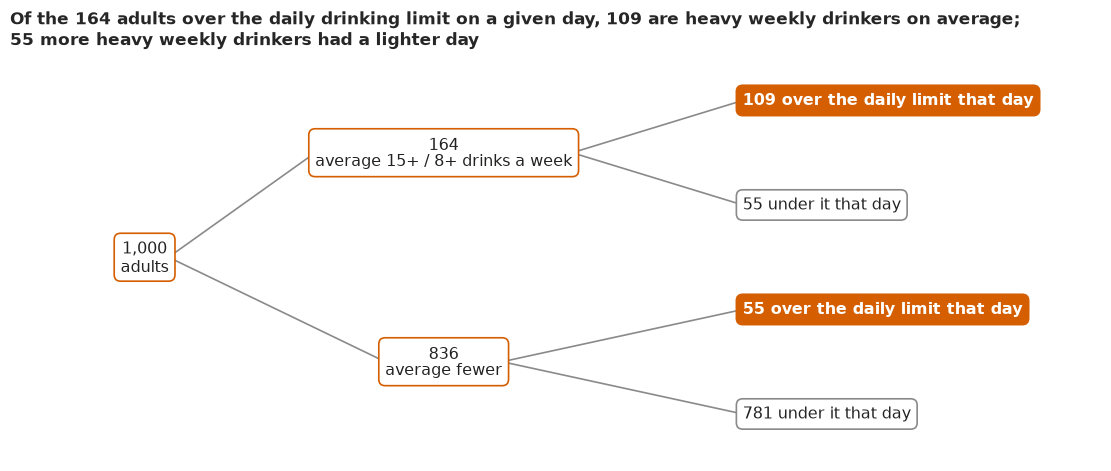

In [24]:
LIM = np.where(male, 28.0, 14.0)
U, DAYS_OVER = np.zeros((SA, N)), np.zeros((SA, N))      # mean g a day; share of days over the limit
for wkv, wt in ((-3 / 7, 4 / 7), (4 / 7, 3 / 7)):
    pr = 1 / (1 + np.exp(-(EF + AWK[:, None] * wkv)))
    loc = AM0 + AS0 * (EA + CWK[:, None] * wkv)
    U[:, keep] += wt * pr * np.exp(loc + (AS0 * TAU[:, None]) ** 2 / 2)
    DAYS_OVER[:, keep] += wt * pr * stats.norm.sf((np.log(LIM[keep]) - loc) / (AS0 * TAU[:, None]))
over1 = np.zeros(N, bool)
over1[p1] = alc1 > LIM[p1]
ALC_ONE = np.average(over1[p1], weights=w1)
usual_over = U > LIM                                     # (S, N): averages over 14 / 7 drinks a week
ALC_USUAL = (usual_over * W).sum(1)
print(f"recall day over the daily limit: observed {ALC_ONE:.3f}; model's expected share of days {q((DAYS_OVER * W).sum(1))}")
print(f"adults over the daily limit on at least one day a week on average: {q(((DAYS_OVER >= 1 / 7) * W).sum(1))}")
print(f"adults averaging more than 14 / 7 drinks a week, i.e. 15+ / 8+ (men / women): {q(ALC_USUAL)}")
print(f"mean grams a day (weighted): one day {np.average(alc1, weights=w1):.1f}; usual {q((U * W).sum(1))}")
# cross-classify: usually over (posterior) against over on day 1 (observed)
p_u = (usual_over * W).sum(1)                                        # P(usually over), per draw
p_d1_given_u = (usual_over * (W * over1)).sum(1) / p_u               # over on day 1 | usually over
p_d1_given_not = ((~usual_over) * (W * over1)).sum(1) / (1 - p_u)    # over on day 1 | not usually over
p_u_given_d1 = (usual_over * (W * over1)).sum(1) / (W * over1).sum()
print(f"of adults over on day 1, usually over: {q(p_u_given_d1)}")
print(f"of adults usually over, under on day 1: {q(1 - p_d1_given_u)}")

fig, ax = plt.subplots(figsize=(11, 4.6))
tree = pub.freq_tree(ax, 1000, p_u, p_d1_given_u, p_d1_given_not, unit="adults", color=LO,
                     split1=("average 15+ / 8+ drinks a week", "average fewer"),
                     split2=("over the daily limit that day", "under it that day"), title=False)
ax.set_title(f"Of the {tree['yes_pos'] + tree['no_pos']} adults over the daily drinking limit on a given day, "
             f"{tree['yes_pos']} are heavy weekly drinkers on average;\n{tree['yes_neg']} more heavy weekly "
             f"drinkers had a lighter day", loc="left", fontsize=12.5);

Three numbers answer three different questions. On 16% of recall days an adult is over the daily
limit. The model's expected share of days, about 15% (15-16%), comes close but sits a little
below it. That share of days is the quantity a daily limit speaks to, and a single day measures
it directly for the population. But it is a share of days, not of people. Asked of people, the
question becomes how often a person goes over. With a threshold we chose, at least one day in
seven, about 30% of adults (29-32%) do so on average. That number is a model extrapolation: it
leans on the upper tail of the log-normal amounts, fitted to people with at most two observed
days, and its interval carries only the uncertainty within that form. And 16% (15-18%) average 15
or more drinks a week (men) or 8 or more (women). The frequency tree, built from the posterior
and the observed first days, shows how poorly a single day sorts people on that last measure. Of
the adults over the daily limit on their recall day, only about two in three are heavy weekly
drinkers on average; the rest had a heavy day. And about a third of the heavy weekly drinkers
were under the limit that day. The two errors balance in the total and stay large for any
individual or any subgroup that drinks differently.

## G · Explaining it to everyone

### The headline as a hypothetical outcome plot

A statistician would show the result as two numbers with an interval, or two overlapping
distributions. The message here is about *noise*, and noise is easiest to see when it moves. A
**hypothetical outcome plot** (HOP) shows one possible outcome per frame, so uncertainty becomes
change over time. Hullman, Resnick & Adar (2015) found that people judge how reliably one quantity
exceeds another better from HOPs than from error bars or violin plots, and Kale, Nguyen, Kay &
Hullman (2019) found that untrained viewers pick out real trends from weaker evidence with them.
The icon array underneath each frame is the format the risk-communication literature recommends
for shares of people (Galesic, Garcia-Retamero & Gigerenzer 2009), with absolute numbers out of a
fixed 100 (Akl et al. 2011).

Each dot is the same 1% of US adults in every frame, a "seat" at one percentile of usual intake
(the 0.5th, 1.5th, ..., 99.5th), highest intake top left. Then, in each of 40 frames, one
posterior draw:

- **left, judged by one day:** the sampled adult nearest that seat's percentile (by weighted
  posterior-median usual intake), on a randomly chosen day of the week, simulated from their usual
  level in this draw with fresh day-to-day noise;
- **right, judged by their usual diet:** the seat's percentile of the population's usual intakes
  in this draw, orange if it is over the line. The orange count is then the population share in
  that draw, so the right grid moves exactly as much as our uncertainty about the headline.

**Failure: colouring 100 particular people.** The obvious right grid colours the 100 sampled
adults at those seats by their *own* posterior usual intakes. It flickers far more than the
headline, over about 82-93 in the cell below, because two recalls leave each person's usual intake
uncertain, and across 100 particular people that uncertainty does not average out the way it does
across 4,863. Shown as a share, it would overstate our uncertainty about the population several
times over; the seat-percentile version moves only as much as the headline does. The first and
last frames, which the GIF holds longest and which a preview shows, are the draws closest to the
middle.

one day                   60-83 of 100 over across frames (65-78 in 9 of 10), 35 dots change per frame, 1 never change
usual diet                84-88 of 100 over across frames (84-87 in 9 of 10), 1 dots change per frame, 96 never change
seats' own usual intakes  82-93 of 100 over across frames (82-91 in 9 of 10), 14 dots change per frame, 43 never change
held frames: first 70 and 86, last 70 and 86; population usual share [0.85 0.86 0.88]


wrote E108_usual_salt_intake.gif: 40 frames, 640x392 px, 1.0 MB


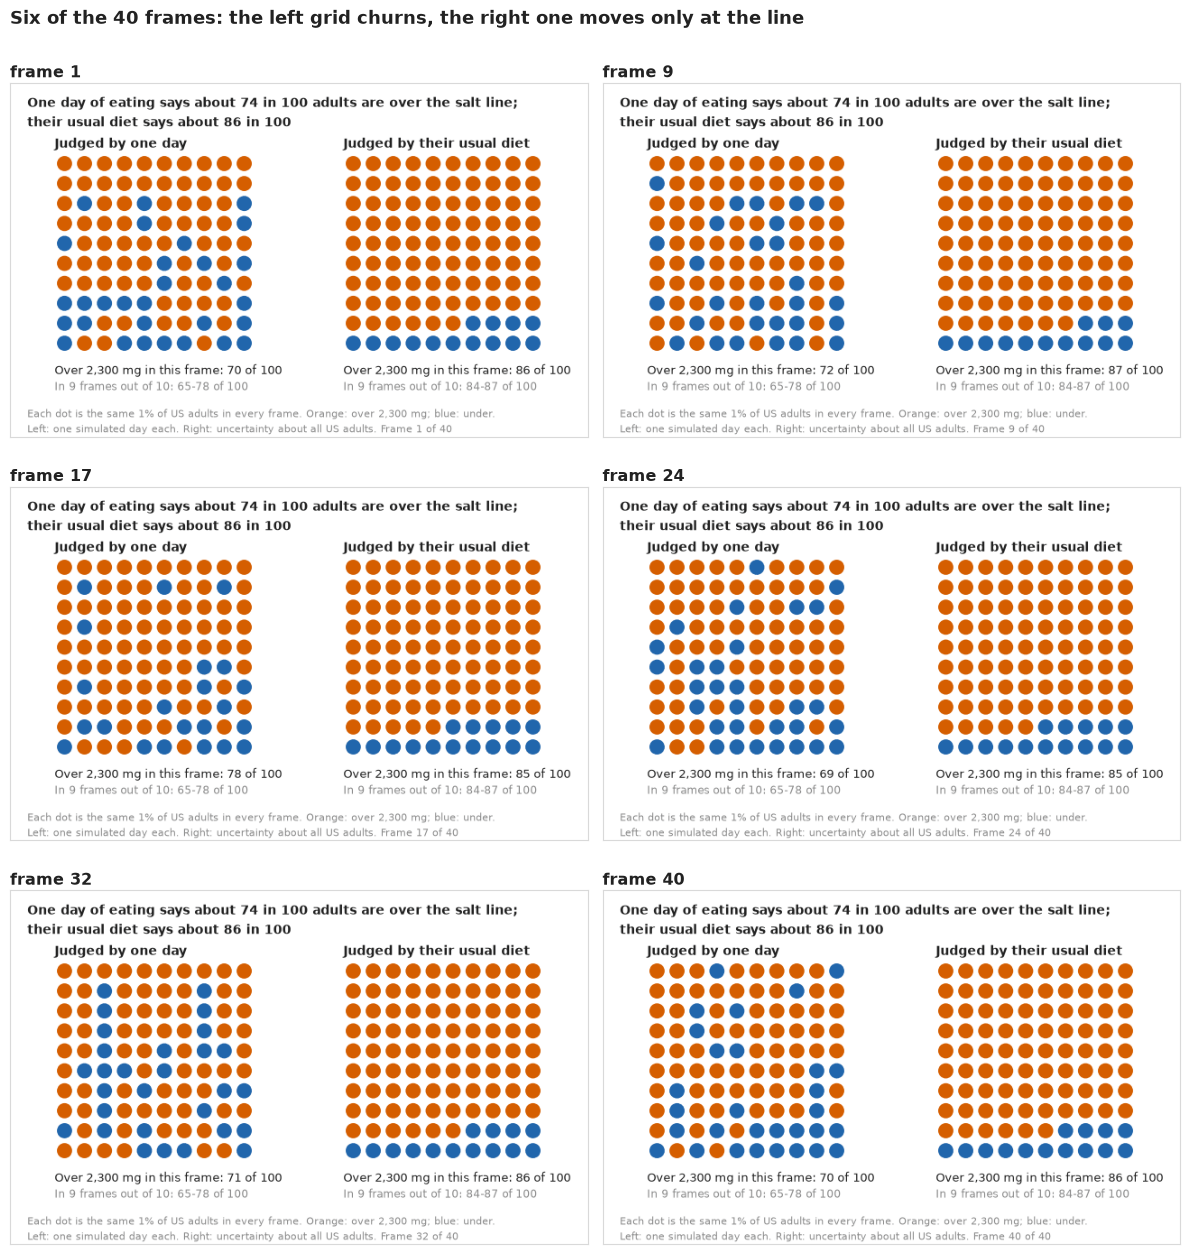

In [25]:
t0 = time.time()
r7 = np.random.default_rng(RANDOM_SEED)
med_usual = np.median(T_SAMPLED, 0)
o = np.argsort(med_usual)
cw = np.cumsum(W[o])
SEATS = o[np.searchsorted(cw, (np.arange(100) + 0.5) / 100)][::-1]      # highest usual intake first
NF = 40
fk = r7.choice(S, NF, replace=False)
wkday = r7.random((NF, 100)) < 3 / 7
ONE = ginv(MU[fk][:, SEATS] + GWK_[fk, None] * (wkday - 3 / 7)
           + SWP[fk][:, SEATS] * r7.standard_normal((NF, 100))) > LINE
PCT = 1 - (np.arange(100) + 0.5) / 100                                   # seat i's percentile, top first
TYP = np.array([wquant(T_NEW[k], W, PCT) for k in fk]) > LINE            # population percentiles per draw
# hold the most typical frames first and last
z_ = np.abs(ONE.sum(1) - np.median(ONE.sum(1))) / ONE.sum(1).std() + np.abs(TYP.sum(1) - np.median(TYP.sum(1))) / max(TYP.sum(1).std(), 1)
o_ = np.argsort(z_)
order = np.r_[o_[0], np.sort(o_[2:]), o_[1]]
ONE, TYP, wkday = ONE[order], TYP[order], wkday[order]
cl, cr = ONE.sum(1), TYP.sum(1)
lo_l, hi_l = np.quantile(cl, [0.055, 0.945]).round().astype(int)
lo_r, hi_r = np.quantile(cr, [0.055, 0.945]).round().astype(int)
n1, n2 = round(ONE_DAY * 100), round(np.median(USUAL) * 100)            # the numbers the dots show
IND = T_SAMPLED[fk[order]][:, SEATS] > LINE                             # seats coloured by their own usual intakes
for lab, A_ in (("one day", ONE), ("usual diet", TYP), ("seats' own usual intakes", IND)):
    c_ = A_.sum(1)
    print(f"{lab:25s} {c_.min()}-{c_.max()} of 100 over across frames "
          f"({np.quantile(c_, 0.055):.0f}-{np.quantile(c_, 0.945):.0f} in 9 of 10), "
          f"{np.abs(np.diff(A_, axis=0)).sum(1).mean():.0f} dots change per frame, "
          f"{int(((A_.mean(0) == 0) | (A_.mean(0) == 1)).sum())} never change")
print(f"held frames: first {cl[0]} and {cr[0]}, last {cl[-1]} and {cr[-1]}; population usual share {q(USUAL)}")

fig = plt.figure(figsize=(8, 4.9), dpi=80, layout="none")
axL, axR = fig.add_axes([0.03, 0.23, 0.44, 0.57]), fig.add_axes([0.53, 0.23, 0.44, 0.57])
fig.text(0.03, 0.96, f"One day of eating says about {n1} in 100 adults are over the salt line;",
         fontsize=13, weight="bold", color=INK, va="top")
fig.text(0.03, 0.905, f"their usual diet says about {n2} in 100", fontsize=13, weight="bold", color=INK, va="top")
fig.text(0.03, 0.055, "Each dot is the same 1% of US adults in every frame. Orange: over 2,300 mg; blue: under.",
         fontsize=10, color=MUTED)
foot = fig.text(0.03, 0.012, "", fontsize=10, color=MUTED)


def grid(ax, col, head, cnt, lo, hi):
    ax.clear()
    for i in range(100):
        rr_, cc_ = divmod(i, 10)
        ax.add_patch(plt.Circle((cc_ + 0.5, 9.5 - rr_), 0.38, fc=LO if col[i] else HI, ec="none"))
    ax.set_xlim(0, 10); ax.set_ylim(-0.1, 10); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(head, fontsize=12.5, loc="left", color=INK)
    ax.text(0, -0.55, f"Over 2,300 mg in this frame: {cnt} of 100", fontsize=11.5, va="top", color=INK)
    ax.text(0, -1.4, f"In 9 frames out of 10: {lo}-{hi} of 100", fontsize=10.5, va="top", color=MUTED)


def show(k):
    grid(axL, ONE[k], "Judged by one day", int(ONE[k].sum()), lo_l, hi_l)
    grid(axR, TYP[k], "Judged by their usual diet", int(TYP[k].sum()), lo_r, hi_r)
    foot.set_text(f"Left: one simulated day each. Right: uncertainty about all US adults. Frame {k + 1} of {NF}")


GIF = f"{STEM}.gif"                     # written next to the notebook; the site copies {stem}*.gif
frames = pub.save_gif(fig, show, NF, GIF, ms=600)
plt.close(fig)
picks = np.linspace(0, NF - 1, 6).round().astype(int)
sheet = pub.gif_contact_sheet(frames, picks, captions=[f"frame {k + 1}" for k in picks],
                              title="Six of the 40 frames: the left grid churns, the right one moves only at the line")
TIMES["gif"] = time.time() - t0

The still shows what the animation does. On the left, about 70 of the 100 dots are orange in a
typical frame (65-78 in nine frames out of ten), and about 35 dots change colour from one frame to
the next, all over the grid: nearly everyone *could* have a day under the line. On the right,
84-88 dots are orange (84-87 in nine frames out of ten, against the population's 85-88), about
one dot changes per frame, and only the four seats at the line ever change. The two kinds of
flicker mean different things. On the left it means "days differ"; on the right it means "we
are not sure of the exact share", and it is only as large as that uncertainty, a few people in
100 (the own-intake colouring would have shown 82-93). The GIF is
[E108_usual_salt_intake.gif](E108_usual_salt_intake.gif), ready to paste into a message or a
slide:

![Animated figure: two grids of 100 dots, orange if over 2,300 mg of sodium and blue if under. The
left grid, judged by one day, flickers everywhere; the right grid, judged by usual diet, changes
only in the few dots at the line, with 84 to 88 orange.](E108_usual_salt_intake.gif)

A heat map of the same frames gives the *flip rate*, the share of frames in which each dot was
over the line: on the left, the chance that a person's day is over it; on the right, the chance
that the share of adults reaches that seat.

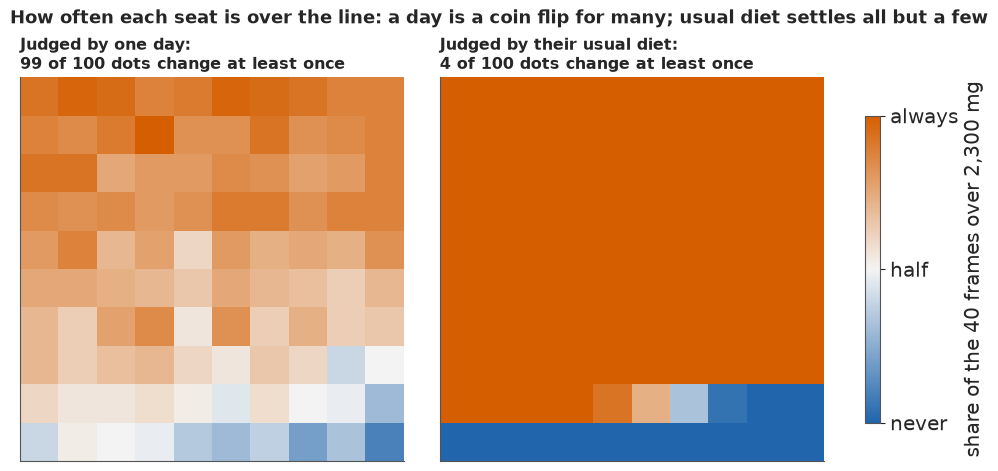

In [26]:
cmap = LinearSegmentedColormap.from_list("hilo", [HI, "#f4f4f4", LO])
fig, axs = plt.subplots(1, 2, figsize=(10, 4.6))
for ax, arr, head in ((axs[0], ONE, "Judged by one day"), (axs[1], TYP, "Judged by their usual diet")):
    im = ax.imshow(arr.mean(0).reshape(10, 10), cmap=cmap, vmin=0, vmax=1)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{head}:\n{int(((arr.mean(0) > 0) & (arr.mean(0) < 1)).sum())} of 100 dots change at least once",
                 loc="left", fontsize=11.5)
cb = fig.colorbar(im, ax=axs, shrink=0.8, ticks=[0, 0.5, 1])
cb.set_label("share of the 40 frames over 2,300 mg")
cb.ax.set_yticklabels(["never", "half", "always"])
fig.suptitle("How often each seat is over the line: a day is a coin flip for many; usual diet settles all but a few",
             x=0.02, ha="left", fontsize=13);

### The statistician's plot, and what the public version adds

The conventional display of the same result is a dot-and-interval chart: one estimate per group
with its 89% interval, and the one-day share for comparison.

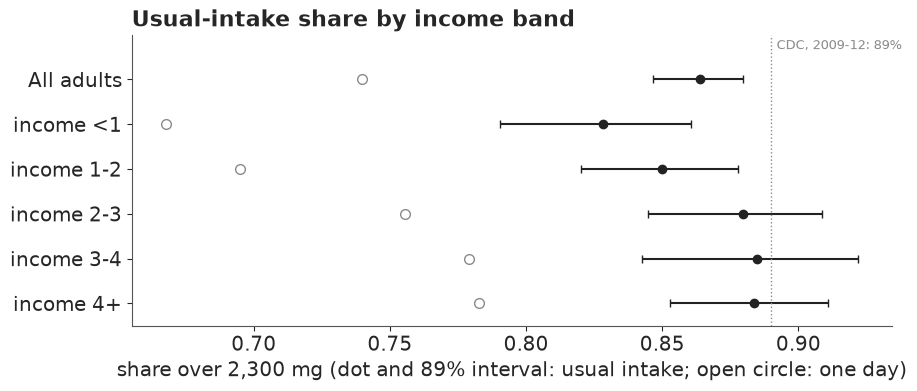

In [27]:
grp = [("All adults", ONE_DAY, USUAL)] + [(f"income {k}", *BAND[k]) for k in PIR_LAB[:5]]
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, (lab, od, us) in enumerate(grp):
    lo_, md_, hi_ = np.quantile(us, [0.055, 0.5, 0.945])
    ax.errorbar(md_, i, xerr=[[md_ - lo_], [hi_ - md_]], fmt="o", color=INK, capsize=3)
    ax.plot(od, i, "o", mfc="white", mec=MUTED, ms=7)
ax.axvline(0.89, color=MUTED, ls=":", lw=1)
ax.text(0.892, -0.75, "CDC, 2009-12: 89%", fontsize=9, color=MUTED, va="center")
ax.set_yticks(range(len(grp)), [g[0] for g in grp]); ax.set_ylim(len(grp) - 0.5, -1.0)
ax.set_xlabel("share over 2,300 mg (dot and 89% interval: usual intake; open circle: one day)")
ax.set_title("Usual-intake share by income band", loc="left");

For a reader trained in statistics it is complete. For anyone else, it asks three things they
cannot do: read a share as people, read an interval as uncertainty rather than a range of people,
and understand why the open circle is a different kind of number. Hofman, Goldstein & Hullman
(2020) found that intervals like these lead readers to overestimate effects, and Correll &
Gleicher (2014) that error bars invite a "within the bar" misreading.

The public version replaces each row with a small icon array of 100 adults. The solid icons are
the low end of the 89% interval (we are fairly confident at least this many are over), the
hatched ones run up to the high end, and the grey ones are adults usually under the line. Read
from the poorest band to the richest, it is a ladder that climbs from about 83 in 100 below the
poverty line to about 88 at twice it and above. The
one-day shares are left off on purpose: beside each array they would invite reading the
difference from one day as noise removed, and part D showed that the model does not reproduce
the one-day income gap, so that reading is not available. For all adults together, where the
model does reproduce the one-day share, the HOP makes that comparison.

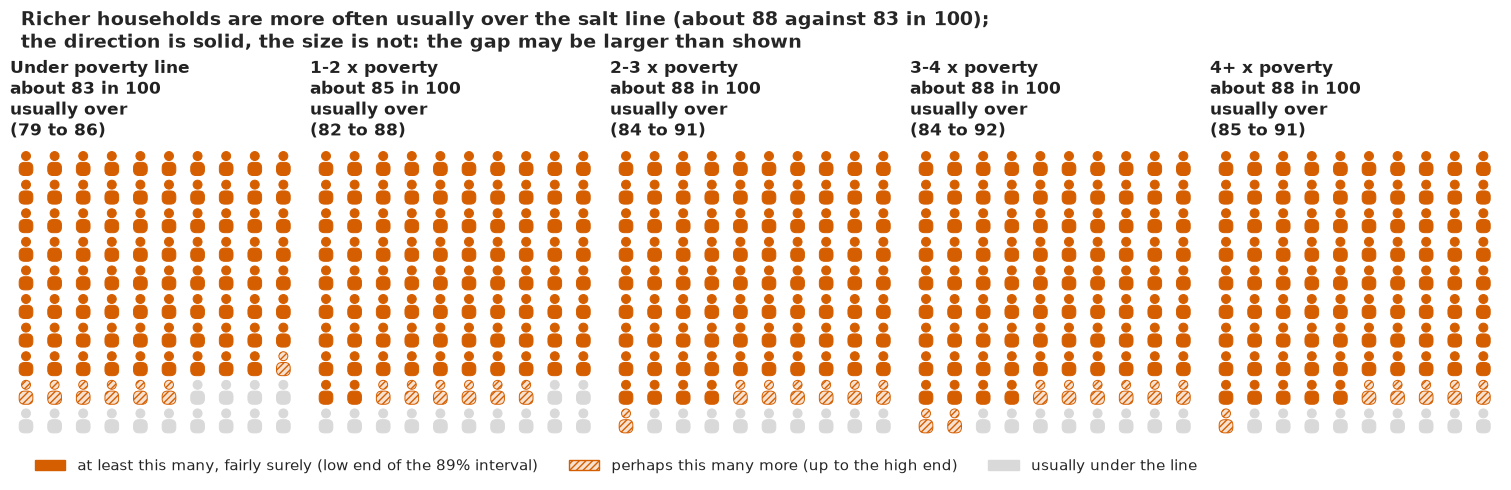

In [28]:
fig, axs = plt.subplots(1, 5, figsize=(15, 4.4))
BLAB = {"<1": "Under poverty line", "1-2": "1-2 x poverty", "2-3": "2-3 x poverty",
        "3-4": "3-4 x poverty", "4+": "4+ x poverty"}
MID = {}
for ax, k in zip(axs, PIR_LAB[:5]):
    lo_, md_, hi_ = pub.freq_range(BAND[k][1])
    pub.icon_array(ax, lo_, md_, hi_, color=LO, key=False,
                   title=f"{BLAB[k]}\nabout {md_} in 100 usually over\n({lo_} to {hi_})")
    MID[k] = md_
light_lo = tuple(0.18 * np.array(to_rgb(LO)) + 0.82)
fig.legend(handles=[Patch(fc=LO, ec=LO, label="at least this many, fairly surely (low end of the 89% interval)"),
                    Patch(fc=light_lo, ec=LO, hatch="/////", label="perhaps this many more (up to the high end)"),
                    Patch(fc=LIGHT, ec=LIGHT, label="usually under the line")],
           loc="upper left", ncols=3, frameon=False, fontsize=11, bbox_to_anchor=(0.01, 0.0))
fig.suptitle(f"Richer households are more often usually over the salt line (about {MID['4+']} against "
             f"{MID['<1']} in 100);\nthe direction is solid, the size is not: the gap may be larger "
             f"than shown", x=0.01, ha="left", fontsize=13.5);

The ladder trades the precision of the interval chart for something a reader can count. Its
pitfall is the same as every icon array's: the hatched icons must be explained in the figure, and
five arrays side by side invite counting differences that are within the uncertainty (the middle
three bands overlap almost completely).

### Words pinned to numbers

Finally, the probability in the plain-words summary. The IPCC scale (Mastrandrea et al. 2010)
gives each likelihood word a range; Budescu, Broomell & Por (2009) found that readers interpret
the words far more consistently when the number travels with them, and van der Bles et al. (2020)
that numeric uncertainty barely dents trust while vague words do. So each claim gets both.

It is *virtually certain* (>99%) that more adults are usually over the line than a single day suggests. We have *medium confidence* in the 86 in 100 itself: two days per person is the minimum, recalls miss salt added at the table, and our ranges are probably a little too narrow.
It is *very likely* (98.9%) that the poorest income band is usually over the line less often than the richest. We have *medium confidence* in that direction: income bands also differ in age, sex and diet patterns, and the model understates the one-day gap, so the size of the usual gap is uncertain.
headline: one day 74%; usual 86% (85%-88%)


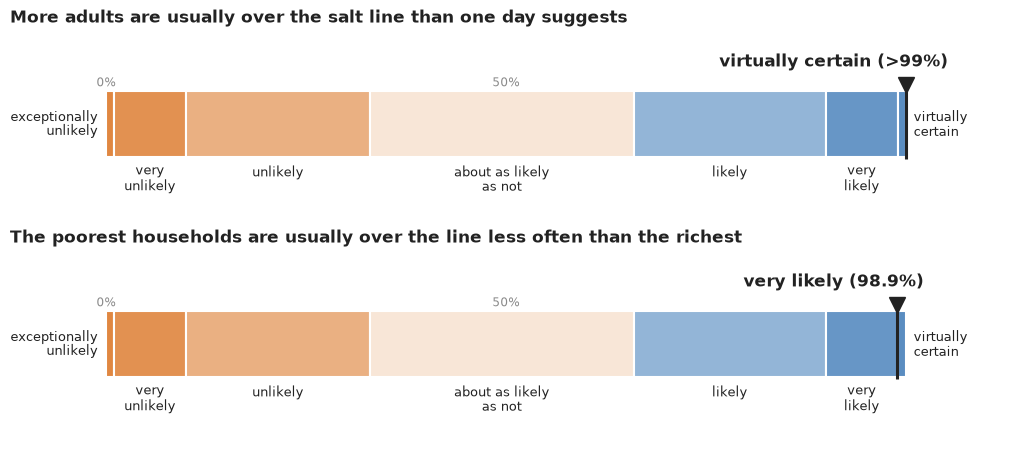

In [29]:
fig, axs = plt.subplots(2, 1, figsize=(10, 4.4))
pub.word_strip(axs[0], P_HIGHER, "More adults are usually over the salt line than one day suggests")
pub.word_strip(axs[1], P_GAP, "The poorest households are usually over the line less often than the richest")
# a probability next to a band edge (99%) gets a decimal, so the marker and its number agree
gap_txt = f"{P_GAP:.1%}" if 0.985 <= P_GAP < 0.995 else pub.fmt_pct(P_GAP)
for t_ in axs[1].texts:
    if t_.get_text() == f"{pub.calibrated_word(P_GAP)} ({pub.fmt_pct(P_GAP)})":
        t_.set_text(f"{pub.calibrated_word(P_GAP)} ({gap_txt})")
print(pub.how_sure(P_HIGHER, "more adults are usually over the line than a single day suggests", "medium",
                   "two days per person is the minimum, recalls miss salt added at the table, and our ranges are "
                   "probably a little too narrow").replace("in that figure", f"in the {n2} in 100 itself"))
print(pub.how_sure(P_GAP, "the poorest income band is usually over the line less often than the richest", "medium",
                   "income bands also differ in age, sex and diet patterns, and the model understates the "
                   "one-day gap, so the size of the usual gap is uncertain")
      .replace(f"({pub.fmt_pct(P_GAP)})", f"({gap_txt})").replace("in that figure", "in that direction"))
print(f"headline: one day {ONE_DAY:.0%}; usual {np.median(USUAL):.0%} "
      f"({np.quantile(USUAL, 0.055):.0%}-{np.quantile(USUAL, 0.945):.0%})")

Some caveats travel with every number here, and the "medium confidence" says so. Two recalls per
person is the minimum the method needs. A 24-hour recall misses salt added at the table (the food
database already counts salt typically added in cooking), and recalls tend to under-report
sodium, so intakes are, if anything, low and the share over the line more likely higher than
lower. The survey weights enter the population share, but the design's clustering (masked strata
and primary sampling units) does not enter the posterior, so the intervals are somewhat too
narrow. The model reproduces the weighted one-day share as about 71% rather than 74%, probably
because its covariate effects are additive and its variance split is shared across income bands;
a model that fitted the weighted share would probably lift the headline by a point or two. And the
real day-to-day spread near the line is smaller than the model assumes, which shifts the share by
an amount, and in a direction, we have not measured. The 2,300 mg line is a population target,
not a personal threshold.

In [30]:
TIMES["total"] = time.time() - T_START
print({k: round(v) for k, v in TIMES.items()})

{'toy': 4, 'prior': 0, 'fit_centred': 9, 'fit_sodium': 10, 'fit_prior1': 10, 'ppc': 0, 'ppc_pairs': 0, 'derived': 11, 'fit_log': 10, 'part_E': 29, 'fit_income': 15, 'fit_alcohol': 41, 'gif': 11, 'total': 186}


## Summary

* **Close to the CDC's nine in ten, and one day would have said three in four.** About 86% of US
  adults (89% interval 85-88%) usually eat more than 2,300 mg of sodium a day in NHANES 2017-2018,
  against 74% on a single recall day; the usual share is higher in every posterior draw. The CDC's
  89% for 2009-2012, itself a usual-intake estimate, sits just outside our interval, and the gap
  may not be real: our intervals leave out the survey's clustering, and the model reads the
  weighted one-day share about 3 points low.
* **Noise inflates the side of the line the middle is not on.** The median adult usually eats
  about 3,400 mg, so removing day-to-day noise moves people over 2,300 mg; in the tails it does
  the opposite (under 1,500 mg: 9% one day, 1% usual; over 5,000 mg: 17% against 11%). The tail
  shares depend on the transformation more than the headline does (14% over 5,000 mg on a log
  scale). The replicate check passes on the day-to-day correlation, but real day-to-day changes
  have heavier tails than the normal error.
* **The back-transform matters.** Usual intake is a person's mean day; reporting their median day
  gives 82% instead of 86%.
* **A funnel, and a mixed fix.** Both variance hierarchies centred gave divergences at small
  between-person pooling sd; both non-centred mixed badly. Centring the well-identified
  within-person scales and non-centring the between-person ones sampled cleanly in about 10 s.
* **The second day identifies the split, and a few hundred are enough.** With person effects
  integrated out, the within-person share of variance is 0.65 (0.63-0.67) with both days, exactly
  its prior with one day (and a headline anywhere from the high 70s to the low 90s), and already
  narrowed from the prior's 0.28-0.84 to 0.62-0.76 with 300 second days.
* **The direction of the income gap is solid, its size is not.** Usual intake puts the richest
  band about 6 points (1-10) above the poorest, and it is very likely (98.9%) that the poorest
  band is usually over less often. But that model's own single days give a gap of about 6 points
  against 10 unweighted and 11.5 weighted in the data, so it understates the gap. Letting the
  variance split vary by income reproduces the one-day gap (9 points, 4-15) and gives a usual gap
  of about 7 (2-12). These are group differences, not effects of income.
* **For alcohol, one day estimates the share of days, not of people.** A correlated two-part model
  with a never-drinker group from the questionnaire comes close to the 16% of recall days over the
  2020-2025 Guidelines' daily limit (about 15% expected). The usual quantities are different:
  about 30% of adults go over it on at least one day in seven (a model extrapolation), and 16%
  average 15 / 8 or more drinks a week (the weekly part of the NIAAA's heavy-drinking
  definition). One day sorts people badly on the last: only about two in three of those over
  on a given day are heavy weekly drinkers, and about a third of the heavy weekly drinkers had a
  lighter day.
* **Show noise as motion.** A HOP of 100 seats makes the difference between "days differ" and
  "we are unsure" visible, as long as the right grid's flicker is only as large as the uncertainty
  about the share, not about 100 particular people. Its still, flip-rate map, icon-array ladder
  and word strip carry the same result to print.

## Try it yourself

1. **Heavier day tails.** Replace the normal day error with a Student-t (free degrees of freedom)
   and redo the usual-intake quadrature with the t. Does the 25,949 mg day stop being an outlier,
   and which of the three shares (1,500, 2,300, 5,000 mg) move?
2. **Potassium.** Fit the same model to `potassium_mg` (Box-Cox $\lambda \approx 0.39$) and compare
   the share below the Adequate Intake (3,400 mg men, 2,600 mg women) on one day and as usual
   intake. Which side of the line is the middle, and does the bias go the way part D predicts?
   (A share below an AI is not a prevalence of inadequacy; say what it is instead.)
3. **Let the data choose the scale.** Make $\lambda$ a parameter of the model (with the Jacobian
   $(\lambda - 1)\sum\log x$ in a `pm.Potential`) instead of fixing it from day 1, and see how much
   the tail shares widen once the transformation's uncertainty is carried through.